# Milestone 1: Formula 1 Podium Prediction

**Course:** CSEN 903 · **Data:** F1 World Championship, 1950–2024 (14 Ergast CSV tables)
**Target:** `podium` = 1 if the driver finishes in the top three (`positionOrder <= 3`).
**Prediction time:** after qualifying, before the race starts. Nothing from the current race, and no standings updated after it, may be used as a feature.

| Member | Role | Owns |
| :--- | :--- | :--- |
| **M1** | Data lead | Audit, cleaning, before/after EDA, report assembly |
| **M2** | Analytics lead | Data-engineering questions Q1–Q3, domain mappings, XAI |
| **M3** | Features lead | Leakage-safe features, split, preprocessing, ablation |
| **M4** | Modeling lead | Baselines, models, tuning, thresholds, inference function |

This notebook currently covers the shared components (Section 1), the data audit (Section 2), cleaning (Section 3) and the data-engineering questions (Section 4).

## 1. Shared Components

Everything the four members must handle the same way: config, plot style, leakage guard, data contract, decision log and the raw data loader. Later sections import from here and never hard-code these values.

In [1]:
# 1.1 Config: seed, split years, scope flags and paths
import re
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Set, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)

RANDOM_SEED: int = 42                      # DEC-001
np.random.seed(RANDOM_SEED)

TRAIN_MAX_YEAR: int = 2019                 # DEC-002: train <= 2019
VAL_YEARS: Tuple[int, int] = (2020, 2021)  #          validation 2020-2021
TEST_MIN_YEAR: int = 2022                  #          test >= 2022

EXCLUDE_INDY_500: bool = True              # DEC-003
SENTINEL_VALUES: List[str] = [r"\N", ""]   # how the CSVs encode a missing value

FIGURES_DIR: Path = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def resolve_dataset_dir() -> Path:
    """Return the first folder that holds results.csv: Kaggle input first, then a local archive/ (DEC-006)."""
    candidates = [
        Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"),
        Path("/kaggle/input/formula-1-world-championship-1950-2020"),
        Path("./archive"),
        Path("../archive"),
        Path("d:/GUC/Semester 9/ACL/Project/Formula 1/archive"),
    ]
    for folder in candidates:
        if (folder / "results.csv").exists():
            return folder.resolve()
    for hit in Path("/kaggle/input").rglob("results.csv"):  # any other Kaggle mount point
        return hit.parent.resolve()
    raise FileNotFoundError("F1 dataset not found. Checked: " + ", ".join(str(c) for c in candidates))


DATASET_DIR: Path = resolve_dataset_dir()
print(f"Dataset: {DATASET_DIR} | figures: {FIGURES_DIR}/ | seed: {RANDOM_SEED}")
print(f"Split: train <= {TRAIN_MAX_YEAR}, validation {VAL_YEARS}, test >= {TEST_MIN_YEAR} | exclude Indy 500: {EXCLUDE_INDY_500}")

Dataset: /Users/marina/Desktop/Formula-1/archive | figures: figures/ | seed: 42
Split: train <= 2019, validation (2020, 2021), test >= 2022 | exclude Indy 500: True


In [2]:
# 1.2 Plot style and figure export (DEC-007)
F1_PALETTE = {
    "crimson": "#E10600",
    "dark": "#15151E",
    "teal": "#00D2BE",
    "blue": "#1E41FF",
    "orange": "#FF8700",
    "green": "#229971",
    "gray": "#7A7A85",
    "light_gray": "#E0E0E6",
}

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "figure.autolayout": False,
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Helvetica", "Arial"],
    "font.family": "sans-serif",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.labelweight": "medium",
    "axes.labelpad": 8,
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 1.0,
    "grid.color": "#E5E5EB",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#E5E5EB",
})


def save_fig(fig_id: str, tight_layout: bool = True, fig_extension: str = "png",
             dpi: int = 300, transparent: bool = False) -> Path:
    """Save the current figure as figures/<fig_id>.<fig_extension> and return its path."""
    file_path = FIGURES_DIR / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(file_path, format=fig_extension, dpi=dpi, transparent=transparent, bbox_inches="tight")
    print(f"[FIGURE SAVED] {file_path}")
    return file_path

In [3]:
# 1.3 Leakage blacklist and guard (DEC-004)

# Columns produced during or after the race. They can never be features.
LEAKAGE_BLACKLIST_COLUMNS: Set[str] = {
    # results.csv outcome columns (positionOrder is used only to build the target)
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId",
    # status.csv / constructor_results.csv
    "status",
    # lap_times.csv / pit_stops.csv
    "lap", "stop", "duration",
    # standings recorded after the race
    "wins", "post_race_points", "post_race_position", "post_race_wins", "post_race_rank",
}

# Name patterns that catch renamed variants of the columns above
LEAKAGE_PATTERNS: List[re.Pattern] = [
    re.compile(r"^fastest.*", re.IGNORECASE),
    re.compile(r"^post_.*", re.IGNORECASE),
    re.compile(r".*current.*", re.IGNORECASE),
    re.compile(r"^finish.*", re.IGNORECASE),
    re.compile(r"^pit_stop_.*", re.IGNORECASE),
    re.compile(r"^lap_time_.*", re.IGNORECASE),
]

# What each of the 14 tables may contribute at prediction time
TABLE_TEMPORAL_AUDIT: Dict[str, str] = {
    "circuits": "PRE-RACE SAFE: Static track characteristics (country, location, altitude, lat, lng).",
    "constructors": "PRE-RACE SAFE: Static constructor identity (name, nationality).",
    "drivers": "PRE-RACE SAFE: Static driver identity (dob/age, nationality).",
    "seasons": "PRE-RACE SAFE: Season year metadata.",
    "races": "PRE-RACE SAFE: Scheduled race calendar, round, circuit, session timestamps.",
    "qualifying": "PRE-RACE SAFE: Concluded before lights-out. Column 'position' MUST be renamed to 'quali_position'.",
    "results": "HYBRID: 'grid', 'constructorId', 'number' are SAFE; 'positionOrder' is TARGET; 11 outcome columns are BLACKLISTED.",
    "status": "POST-RACE LEAKAGE: Describes current race termination reason. Safe only for historical aggregations.",
    "constructor_results": "POST-RACE LEAKAGE: Records current race constructor points. Safe only lagged to t-1.",
    "constructor_standings": "POST-RACE LEAKAGE: Ergast records post-race standings for raceId. Safe only lagged to round t-1.",
    "driver_standings": "POST-RACE LEAKAGE: Ergast records post-race standings for raceId. Safe only lagged to round t-1.",
    "lap_times": "IN-RACE TELEMETRY: 100% Forbidden for current race.",
    "pit_stops": "IN-RACE EVENTS: 100% Forbidden for current race.",
    "sprint_results": "PRE-RACE SAFE (CONDITIONAL): Saturday sprint before Sunday race; features must be prefixed with 'sprint_'.",
}


def assert_leakage_safe(feature_cols: List[str]) -> None:
    """Raise ValueError if a candidate feature is blacklisted or matches a leakage pattern."""
    violations = [
        col for col in feature_cols
        if col.strip() in LEAKAGE_BLACKLIST_COLUMNS or any(p.match(col.strip()) for p in LEAKAGE_PATTERNS)
    ]
    if violations:
        raise ValueError(f"[DATA LEAKAGE] These columns are not known before the race: {violations}")
    print(f"[LEAKAGE CHECK PASSED] All {len(feature_cols)} candidate features respect the pre-race cutoff.")


# Self-test: the guard must reject outcome columns
for forbidden in ["milliseconds", "position", "status", "fastestLapTime", "wins"]:
    try:
        assert_leakage_safe(["grid", "quali_position", forbidden])
    except ValueError:
        continue
    raise AssertionError(f"Leakage guard failed to catch '{forbidden}'")

In [4]:
# 1.4 Data contract for the modeling table (DEC-005) and feature groups
GRAIN: List[str] = ["raceId", "driverId"]   # one row per driver per race
IDENTIFIER_COLUMNS: List[str] = ["raceId", "driverId", "constructorId", "date", "year"]
TARGET_COLUMN: str = "podium"

# Feature names by group. Ablation and XAI loop over this dict.
FEATURE_GROUPS: Dict[str, List[str]] = {
    "grid": ["grid", "pit_start", "front_row", "teammate_grid_diff"],
    "qualifying": ["quali_position", "gap_to_pole", "q3_reached", "missing_quali_flag"],
    "driver_form": ["driver_rolling_podium_rate_5", "driver_rolling_avg_finish_5", "driver_career_podium_rate"],
    "constructor_form": ["constructor_rolling_podium_rate_5", "constructor_rolling_points_5"],
    "standings": ["driver_pre_race_points", "driver_pre_race_rank",
                  "constructor_pre_race_points", "constructor_pre_race_rank"],
    "context": ["field_size", "round", "is_home_race", "circuit_historical_podium_rate"],
    "sprint": ["sprint_position", "sprint_points"],
}


def validate_data_contract(df: pd.DataFrame, feature_cols: Optional[List[str]] = None,
                           enforce_grain_only: bool = False) -> bool:
    """Check the contract: unique (raceId, driverId), non-null identifiers, binary target, leakage-safe features."""
    assert set(GRAIN) <= set(df.columns), "Dataframe is missing key columns 'raceId' or 'driverId'."
    n_duplicates = df.duplicated(subset=GRAIN).sum()
    assert n_duplicates == 0, f"Grain violation: Found {n_duplicates} duplicate (raceId, driverId) rows!"
    if enforce_grain_only:
        print(f"[CONTRACT PASSED] Grain verified: {len(df):,} unique (raceId, driverId) rows.")
        return True

    for col in IDENTIFIER_COLUMNS + [TARGET_COLUMN]:
        assert col in df.columns, f"Missing required column: '{col}'"
        assert df[col].notna().all(), f"Column '{col}' contains NULL values."
    assert set(df[TARGET_COLUMN].unique()) <= {0, 1}, f"Target '{TARGET_COLUMN}' must be binary {{0, 1}}."

    if feature_cols is not None:
        assert_leakage_safe(feature_cols)
    print(f"[CONTRACT PASSED] Full modeling table contract satisfied across {len(df):,} rows.")
    return True

### 1.5 Decision Log and Leakage Reference

The full log, including the cleaning decisions DEC-008 to DEC-010, is in [`docs/decision_log.md`](docs/decision_log.md).

| Decision ID | Pipeline Stage | Owner | Decision | Rationale & Evidence | Status |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **DEC-001** | Shared Setup | All | Global Random Seed = `42` | Ensures deterministic reproduction across all environments and runs. | **Approved** |
| **DEC-002** | Shared Setup | M3 / All | Temporal Split: Train $\le 2019$, Val $2020\text{–}2021$, Test $\ge 2022$ | Prevents temporal leakage across F1 aero/engine regulation eras; 2022 tests ground-effect generalization. | **Approved** |
| **DEC-003** | Scope / Cleaning | M1 | Exclude Indianapolis 500 ($1950\text{–}1960$) | Run under AAA/USAC Indy regulations on an oval; non-F1 grid contaminates conversion & form baselines. | **Approved** |
| **DEC-004** | Leakage Guard | M3 / M4 | Strict pre-race temporal cutoff & Blacklist | Prediction target is `positionOrder <= 3`. All current-race in-event metrics across 14 tables are forbidden. | **Approved** |
| **DEC-005** | Data Contract | All | Table Grain strictly `(raceId, driverId)` | Exactly one prediction per driver-race entry. Identifiers retained for lineage, target is binary `podium`. | **Approved** |
| **DEC-006** | Environment | M1 | Kaggle & Local path auto-detection | Seamless execution across Kaggle notebooks and local git repositories with zero config tweaks. | **Approved** |
| **DEC-007** | Visual Standards | M2 | Publication-grade Seaborn style & `save_fig()` | Enforces visual cohesion and automatic 300-DPI exports to `figures/` for report assembly. | **Approved** |

**Leakage by table**
- **Safe before the race:** `circuits`, `constructors`, `drivers`, `seasons`, `races`, `qualifying` (rename `position` to `quali_position`).
- **`results`:** only `grid`, `constructorId` and `number` are features. `positionOrder` defines the target. The other 11 columns are blacklisted.
- **Forbidden for the current race:** `lap_times`, `pit_stops`.
- **Recorded after the race:** `driver_standings`, `constructor_standings`, `constructor_results`. Use them only lagged to the previous round.

In [5]:
# 1.6 Raw data loader
def load_raw_datasets(dataset_dir: Path, sentinels: List[str] = SENTINEL_VALUES) -> Dict[str, pd.DataFrame]:
    """Load every CSV in dataset_dir as {table_name: DataFrame}, reading the sentinels as NaN.

    Treat the result as read-only. All cleaning works on copies, so the raw tables stay
    available for the before/after comparison.
    """
    csv_paths = sorted(dataset_dir.glob("*.csv"))
    if not csv_paths:
        raise FileNotFoundError(f"No CSV files found in {dataset_dir}")
    return {path.stem: pd.read_csv(path, na_values=sentinels, low_memory=False) for path in csv_paths}


raw_dataframes = load_raw_datasets(DATASET_DIR)
print(f"Loaded {len(raw_dataframes)} tables: {', '.join(raw_dataframes)}")

Loaded 14 tables: circuits, constructor_results, constructor_standings, constructors, driver_standings, drivers, lap_times, pit_stops, qualifying, races, results, seasons, sprint_results, status


---
# 2. Step 1: Data Audit (M1)

## Task 1: Raw Table Inventory

Confirm that all 14 tables loaded and record their size, missingness and column types. `raw_dataframes` is only read here, never changed.

In [6]:
# Task 1.1: the 14 expected tables are present and non-empty
EXPECTED_TABLES: Set[str] = {
    "circuits", "constructor_results", "constructor_standings", "constructors", "driver_standings",
    "drivers", "lap_times", "pit_stops", "qualifying", "races", "results", "seasons", "sprint_results", "status",
}
assert set(raw_dataframes) == EXPECTED_TABLES, f"Table mismatch: {set(raw_dataframes) ^ EXPECTED_TABLES}"
assert all(len(df) > 0 for df in raw_dataframes.values()), "A table loaded empty"

inventory_summary_df = pd.DataFrame.from_dict({
    name: {
        "rows": len(df),
        "cols": df.shape[1],
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
        "null_cells": int(df.isna().sum().sum()),
        "null_pct": round(df.isna().mean().mean() * 100, 2),
        "dtypes": ", ".join(f"{n} {dtype}" for dtype, n in df.dtypes.astype(str).value_counts().items()),
    }
    for name, df in raw_dataframes.items()
}, orient="index")
display(inventory_summary_df)

total_rows = inventory_summary_df["rows"].sum()
print(f"Total: {total_rows:,} rows, of which lap_times holds {len(raw_dataframes['lap_times']) / total_rows:.1%}")

,rows,cols,memory_mb,null_cells,null_pct,dtypes
circuits,77,9,0.03,0,0.00,"5 object, 2 int64, 2 float64"
constructor_results,12625,5,0.77,12608,19.97,"3 int64, 1 float64, 1 object"
constructor_standings,13391,7,1.36,0,0.00,"5 int64, 1 float64, 1 object"
constructors,212,5,0.06,0,0.00,"4 object, 1 int64"
driver_standings,34863,7,3.55,0,0.00,"5 int64, 1 float64, 1 object"
drivers,861,9,0.39,1559,20.12,"7 object, 1 int64, 1 float64"
lap_times,589081,6,58.99,0,0.00,"5 int64, 1 object"
pit_stops,11371,7,1.82,0,0.00,"5 int64, 2 object"
qualifying,10494,9,2.06,11668,12.35,"6 int64, 3 object"
races,1125,18,0.72,11349,56.04,"14 object, 4 int64"


Total: 701,433 rows, of which lap_times holds 84.0%


In [7]:
# Task 1.2: column types and non-null counts for every table
for name, df in raw_dataframes.items():
    print(f"\n=== {name} ===")
    df.info()


=== circuits ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

=== constructor_results ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId        

In [8]:
# Task 1.3: summary statistics for the two tables the pipeline is built on
display(raw_dataframes["results"].describe().T.round(2))
display(raw_dataframes["qualifying"].describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
resultId,26759.0,13380.98,7726.13,1.00,6690.50,13380.00,20069.50,26764.00
raceId,26759.0,551.69,313.27,1.00,300.00,531.00,811.00,1144.00
driverId,26759.0,278.67,282.70,1.00,57.00,172.00,399.50,862.00
constructorId,26759.0,50.18,61.55,1.00,6.00,25.00,63.00,215.00
number,26753.0,18.15,15.58,0.00,7.00,16.00,24.00,208.00
grid,26759.0,11.13,7.20,0.00,5.00,11.00,17.00,34.00
position,15806.0,8.02,4.84,1.00,4.00,8.00,11.00,33.00
positionOrder,26759.0,12.79,7.67,1.00,6.00,12.00,18.00,39.00
points,26759.0,1.99,4.35,0.00,0.00,0.00,2.00,50.00
laps,26759.0,46.30,29.50,0.00,23.00,53.00,66.00,200.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
qualifyId,10494.0,NaN,NaN,NaN,5262.482847,3046.588486,1.0,2625.25,5249.5,7893.75,10551.0
raceId,10494.0,NaN,NaN,NaN,624.600915,428.298147,1.0,160.0,870.0,1006.0,1144.0
driverId,10494.0,NaN,NaN,NaN,343.002287,389.586448,1.0,17.0,60.0,822.0,862.0
constructorId,10494.0,NaN,NaN,NaN,47.91843,73.217993,1.0,4.0,9.0,31.0,215.0
number,10494.0,NaN,NaN,NaN,18.786449,18.447502,0.0,7.0,14.0,22.0,99.0
position,10494.0,NaN,NaN,NaN,11.195826,6.260374,1.0,6.0,11.0,16.0,28.0
q1,10338,9146,1:20.382,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
q2,5847,5473,1:26.161,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
q3,3629,3470,1:33.008,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Task 1.4: key facts about results and qualifying
races_year = raw_dataframes["races"][["raceId", "year"]]
raw_with_year = raw_dataframes["results"].merge(races_year, on="raceId")       # raw results + season
quali_with_year = raw_dataframes["qualifying"].merge(races_year, on="raceId")  # raw qualifying + season

raw_podium_rate = (raw_with_year["positionOrder"] <= 3).mean() * 100
print(f"results: {len(raw_with_year):,} rows, {raw_with_year['raceId'].nunique():,} races, "
      f"seasons {raw_with_year['year'].min()}–{raw_with_year['year'].max()}, raw podium rate {raw_podium_rate:.2f}%")

# positionText is the finishing position, or a letter code when the driver was not classified
codes = raw_with_year.loc[~raw_with_year["positionText"].str.isdigit(), "positionText"]
print(f"positionText letter codes: {codes.value_counts().to_dict()}")

print(f"qualifying: {len(quali_with_year):,} rows, seasons {quali_with_year['year'].min()}–{quali_with_year['year'].max()}")
print("Missing qualifying times (%):", (raw_dataframes["qualifying"][["q1", "q2", "q3"]].isna().mean() * 100).round(1).to_dict())

results: 26,759 rows, 1,125 races, seasons 1950–2024, raw podium rate 12.69%
positionText letter codes: {'R': 8897, 'F': 1368, 'W': 336, 'N': 190, 'D': 151, 'E': 9}
qualifying: 10,494 rows, seasons 1994–2024
Missing qualifying times (%): {'q1': 1.5, 'q2': 44.3, 'q3': 65.4}


## Task 2: Primary Keys and Referential Integrity

Every table must have a unique, non-null key, and every foreign key must point to an existing parent row. The one known exception is `results` on `(raceId, driverId)`, which has shared-drive duplicates. They are measured here and resolved in Task 6.

In [10]:
# Task 2.1: each key is unique and non-null
TABLE_KEYS: List[Tuple[str, List[str]]] = [
    ("circuits", ["circuitId"]),
    ("constructors", ["constructorId"]),
    ("drivers", ["driverId"]),
    ("races", ["raceId"]),
    ("seasons", ["year"]),
    ("status", ["statusId"]),
    ("results", ["resultId"]),
    ("qualifying", ["qualifyId"]),
    ("sprint_results", ["resultId"]),
    ("constructor_results", ["constructorResultsId"]),
    ("constructor_standings", ["constructorStandingsId"]),
    ("driver_standings", ["driverStandingsId"]),
    ("qualifying", GRAIN),
    ("sprint_results", GRAIN),
    ("lap_times", GRAIN + ["lap"]),
    ("pit_stops", GRAIN + ["stop"]),
]

key_report = []
for table, key in TABLE_KEYS:
    df = raw_dataframes[table]
    n_null = int(df[key].isna().any(axis=1).sum())
    n_duplicate = int(df.duplicated(subset=key).sum())
    assert n_null == 0 and n_duplicate == 0, f"{table} {key}: {n_null} null and {n_duplicate} duplicate keys"
    key_report.append({"table": table, "key": " + ".join(key), "rows": len(df), "null": n_null, "duplicate": n_duplicate})
display(pd.DataFrame(key_report))

,table,key,rows,null,duplicate
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,seasons,year,75,0,0
5,status,statusId,139,0,0
6,results,resultId,26759,0,0
7,qualifying,qualifyId,10494,0,0
8,sprint_results,resultId,360,0,0
9,constructor_results,constructorResultsId,12625,0,0


In [11]:
# Task 2.2: shared drives break the (raceId, driverId) grain of results
shared_rows = raw_with_year[raw_with_year.duplicated(subset=GRAIN, keep=False)]
print(f"Rows involved in shared drives : {len(shared_rows)}")
print(f"(raceId, driverId) pairs       : {shared_rows.groupby(GRAIN).ngroups}")
print(f"Surplus rows to remove         : {raw_with_year.duplicated(subset=GRAIN).sum()}")

display(shared_rows.groupby("year").agg(rows=("resultId", "size"), races=("raceId", "nunique")).T)
display(shared_rows.sort_values(GRAIN).head(4)[["year", "raceId", "driverId", "constructorId", "grid", "positionOrder", "positionText"]])

Rows involved in shared drives : 176
(raceId, driverId) pairs       : 85
Surplus rows to remove         : 91


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
rows,8,8,6,30,33,33,24,16,6,2,4,2,2,2
races,3,2,3,5,5,4,6,5,3,1,2,1,1,1


,year,raceId,driverId,constructorId,grid,positionOrder,positionText
13188,1978,540,229,54,0,26,F
13191,1978,540,229,57,0,29,F
17362,1964,717,373,172,1,7,7
24298,1964,717,373,172,1,12,R


In [12]:
# Task 2.3: foreign keys. An anti-join counts child rows whose key has no parent row.
PARENT_TABLE = {"raceId": "races", "driverId": "drivers", "constructorId": "constructors",
                "statusId": "status", "circuitId": "circuits"}
FOREIGN_KEYS = {
    "results": ["raceId", "driverId", "constructorId", "statusId"],
    "qualifying": ["raceId", "driverId", "constructorId"],
    "sprint_results": ["raceId", "driverId", "constructorId", "statusId"],
    "races": ["circuitId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results": ["raceId", "constructorId"],
    "driver_standings": ["raceId", "driverId"],
    "pit_stops": ["raceId", "driverId"],
    "lap_times": ["raceId", "driverId"],
}

fk_report = []
for child, keys in FOREIGN_KEYS.items():
    for key in keys:
        parent = PARENT_TABLE[key]
        child_keys = raw_dataframes[child][key].dropna()
        n_orphans = int((~child_keys.isin(raw_dataframes[parent][key])).sum())
        assert n_orphans == 0, f"{child}.{key}: {n_orphans} rows have no match in {parent}"
        fk_report.append({"child": f"{child}.{key}", "parent": f"{parent}.{key}", "orphans": n_orphans})
print(f"All {len(fk_report)} foreign keys resolve with zero orphans.")
display(pd.DataFrame(fk_report))

All 22 foreign keys resolve with zero orphans.


,child,parent,orphans
0,results.raceId,races.raceId,0
1,results.driverId,drivers.driverId,0
2,results.constructorId,constructors.constructorId,0
3,results.statusId,status.statusId,0
4,qualifying.raceId,races.raceId,0
5,qualifying.driverId,drivers.driverId,0
6,qualifying.constructorId,constructors.constructorId,0
7,sprint_results.raceId,races.raceId,0
8,sprint_results.driverId,drivers.driverId,0
9,sprint_results.constructorId,constructors.constructorId,0


## Task 3: "Before" EDA

Six plots of the raw data, saved as `figures/before_eda_*.png`. Task 8 repeats them on the cleaned data.

[FIGURE SAVED] figures/before_eda_missingness_heatmap.png


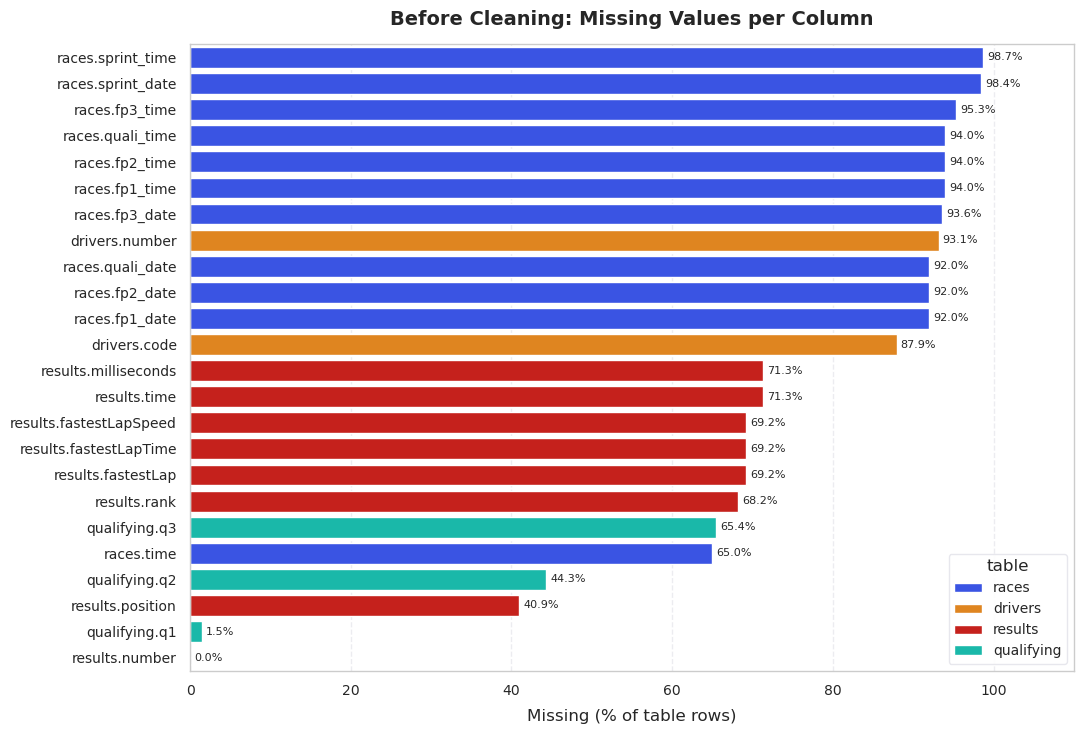

In [13]:
# Task 3.1: missing values per column in the core tables
TABLE_COLORS = {"results": F1_PALETTE["crimson"], "qualifying": F1_PALETTE["teal"],
                "drivers": F1_PALETTE["orange"], "races": F1_PALETTE["blue"]}

missing = pd.concat({t: raw_dataframes[t].isna().mean() * 100 for t in TABLE_COLORS}, names=["table", "column"])
missing = missing[missing > 0].sort_values(ascending=False).rename("missing_pct").reset_index()
missing["label"] = missing["table"] + "." + missing["column"]

fig, ax = plt.subplots(figsize=(11, 7.5))
sns.barplot(data=missing, x="missing_pct", y="label", hue="table", palette=TABLE_COLORS, dodge=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set(title="Before Cleaning: Missing Values per Column", xlabel="Missing (% of table rows)", ylabel="", xlim=(0, 110))
save_fig("before_eda_missingness_heatmap")
plt.show()

[FIGURE SAVED] figures/before_eda_rows_per_season.png


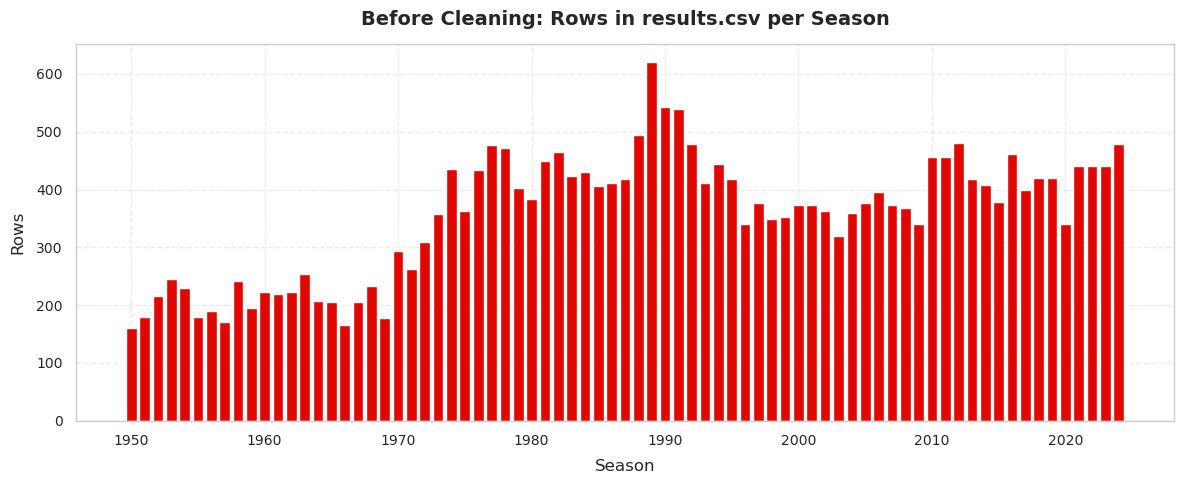

Largest season: 1989 with 620 rows


In [14]:
# Task 3.2: rows per season
rows_per_season = raw_with_year.groupby("year").size()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(rows_per_season.index, rows_per_season.values, color=F1_PALETTE["crimson"], width=0.8)
ax.set(title="Before Cleaning: Rows in results.csv per Season", xlabel="Season", ylabel="Rows")
save_fig("before_eda_rows_per_season")
plt.show()
print(f"Largest season: {rows_per_season.idxmax()} with {rows_per_season.max()} rows")

[FIGURE SAVED] figures/before_eda_entrants_per_race.png


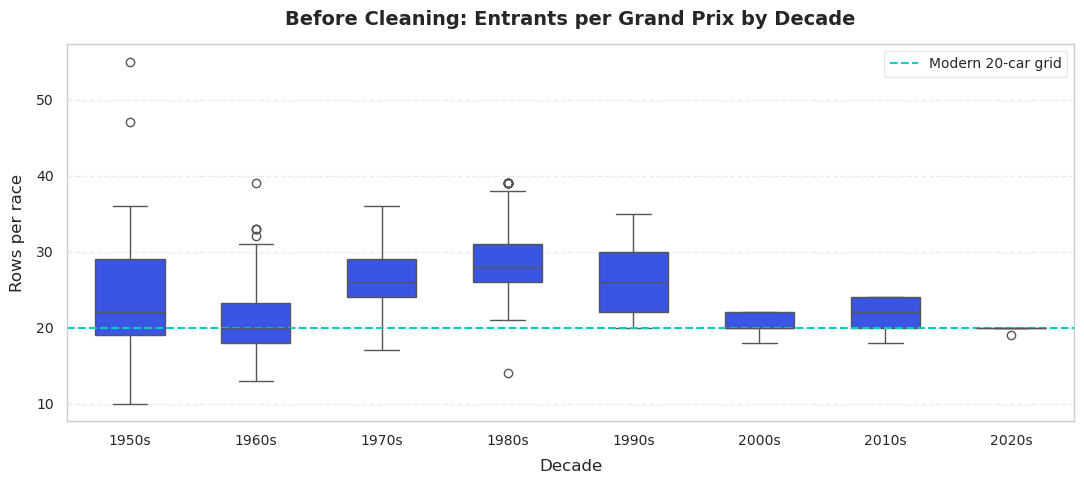

In [15]:
# Task 3.3: entrants per race, by decade
entrants = raw_with_year.groupby(["year", "raceId"]).size().rename("entrants").reset_index()
entrants["decade"] = (entrants["year"] // 10 * 10).astype(str) + "s"

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=entrants, x="decade", y="entrants", color=F1_PALETTE["blue"], width=0.55, ax=ax)
ax.axhline(20, color=F1_PALETTE["teal"], linestyle="--", label="Modern 20-car grid")
ax.set(title="Before Cleaning: Entrants per Grand Prix by Decade", xlabel="Decade", ylabel="Rows per race")
ax.legend()
save_fig("before_eda_entrants_per_race")
plt.show()

[FIGURE SAVED] figures/before_eda_qualifying_coverage.png


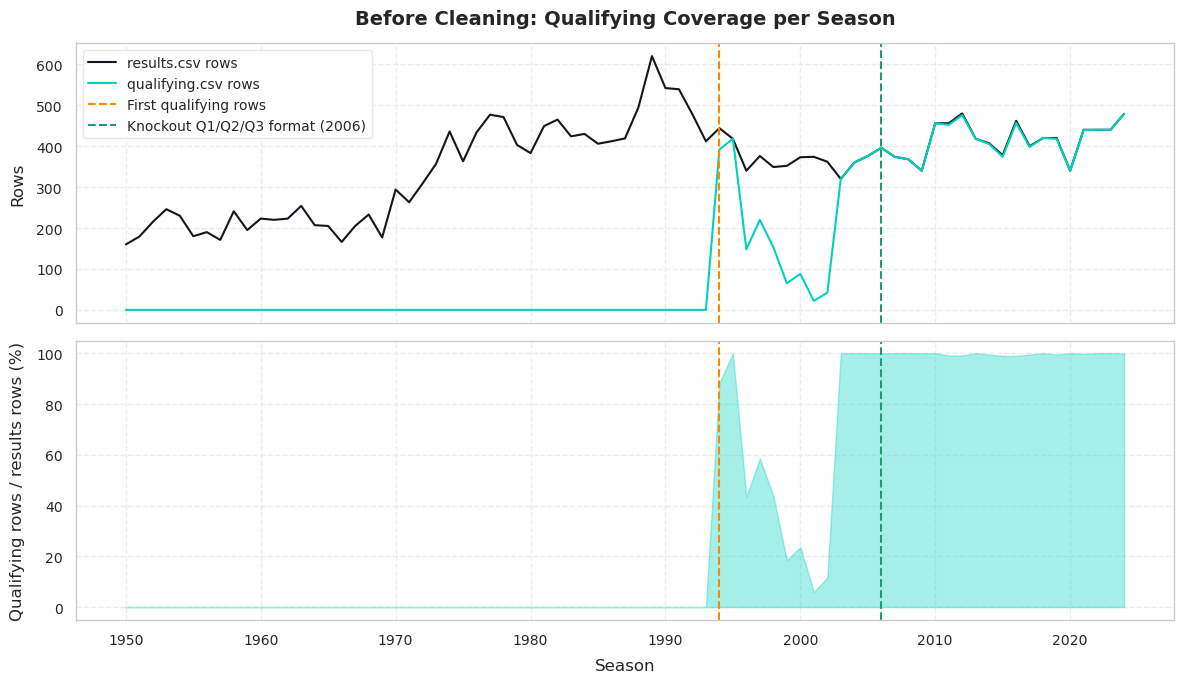

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006
results_rows,412.0,444.0,418.0,340.0,376.0,349.0,352.0,373.0,374.0,362.0,320.0,360.0,376.0,396.0
qualifying_rows,0.0,392.0,418.0,148.0,220.0,153.0,65.0,88.0,22.0,42.0,320.0,360.0,376.0,396.0
coverage_pct,0.0,88.3,100.0,43.5,58.5,43.8,18.5,23.6,5.9,11.6,100.0,100.0,100.0,100.0


In [16]:
# Task 3.4: qualifying coverage per season
coverage = pd.DataFrame({
    "results_rows": raw_with_year.groupby("year").size(),
    "qualifying_rows": quali_with_year.groupby("year").size(),
}).fillna(0)
coverage["coverage_pct"] = coverage["qualifying_rows"] / coverage["results_rows"] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.plot(coverage.index, coverage["results_rows"], color=F1_PALETTE["dark"], label="results.csv rows")
ax1.plot(coverage.index, coverage["qualifying_rows"], color=F1_PALETTE["teal"], label="qualifying.csv rows")
ax2.fill_between(coverage.index, coverage["coverage_pct"], color=F1_PALETTE["teal"], alpha=0.35)
for ax in (ax1, ax2):
    ax.axvline(quali_with_year["year"].min(), color=F1_PALETTE["orange"], linestyle="--", label="First qualifying rows")
    ax.axvline(2006, color=F1_PALETTE["green"], linestyle="--", label="Knockout Q1/Q2/Q3 format (2006)")
ax1.set(title="Before Cleaning: Qualifying Coverage per Season", ylabel="Rows")
ax2.set(xlabel="Season", ylabel="Qualifying rows / results rows (%)")
ax1.legend()
save_fig("before_eda_qualifying_coverage")
plt.show()

display(coverage.loc[1993:2006].round(1).T)

[FIGURE SAVED] figures/before_eda_podium_base_rate.png


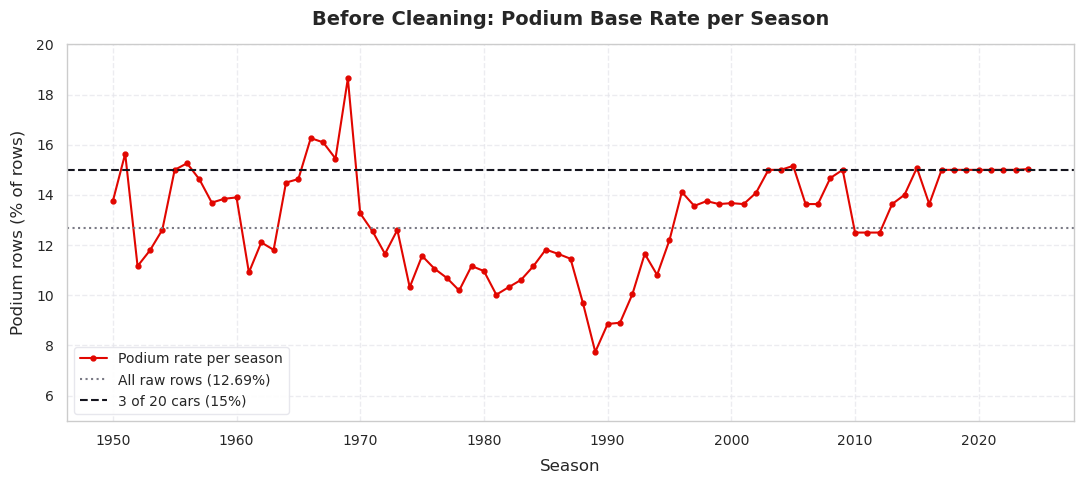

Lowest season: 1989 at 7.74%


In [17]:
# Task 3.5: podium base rate per season
podium_rate_by_season = (raw_with_year["positionOrder"] <= 3).groupby(raw_with_year["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(podium_rate_by_season.index, podium_rate_by_season.values, color=F1_PALETTE["crimson"], marker="o", markersize=3.5,
        label="Podium rate per season")
ax.axhline(raw_podium_rate, color=F1_PALETTE["gray"], linestyle=":", label=f"All raw rows ({raw_podium_rate:.2f}%)")
ax.axhline(15, color=F1_PALETTE["dark"], linestyle="--", label="3 of 20 cars (15%)")
ax.set(title="Before Cleaning: Podium Base Rate per Season", xlabel="Season", ylabel="Podium rows (% of rows)", ylim=(5, 20))
ax.legend(loc="lower left")
save_fig("before_eda_podium_base_rate")
plt.show()
print(f"Lowest season: {podium_rate_by_season.idxmin()} at {podium_rate_by_season.min():.2f}%")

[FIGURE SAVED] figures/before_eda_duplicate_distribution.png


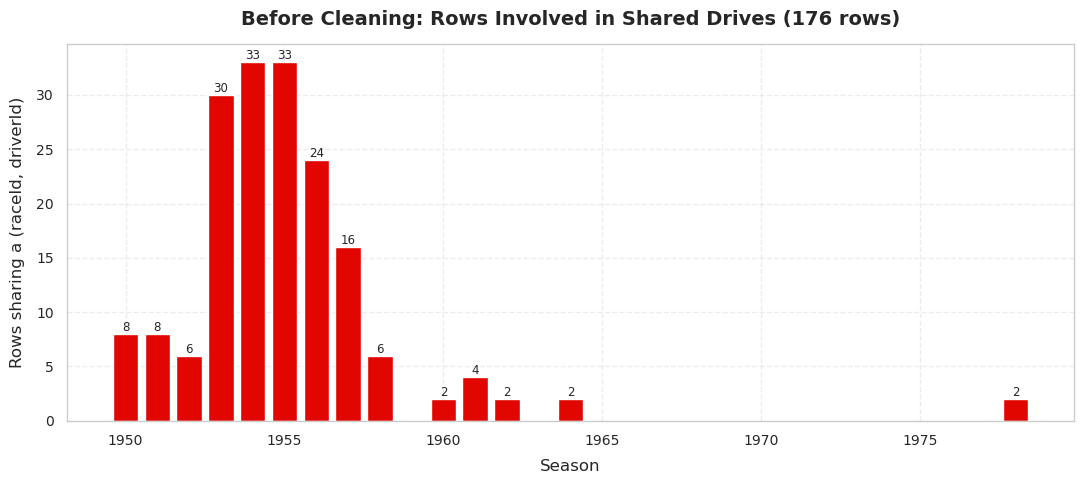

In [18]:
# Task 3.6: where the shared-drive duplicates come from
shared_per_year = shared_rows.groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(shared_per_year.index, shared_per_year.values, color=F1_PALETTE["crimson"], width=0.8)
ax.bar_label(bars, fontsize=8.5)
ax.set(title=f"Before Cleaning: Rows Involved in Shared Drives ({len(shared_rows)} rows)",
       xlabel="Season", ylabel="Rows sharing a (raceId, driverId)")
save_fig("before_eda_duplicate_distribution")
plt.show()

---
# 3. Step 2: Data Cleaning (M1)

## Task 4: Types and Sentinels

Work on copies in `cleaned_dataframes` and give each column its real type: dates become datetimes, and lap-time strings such as `"1:24.312"` become seconds. Missing `q2`/`q3` values are kept, because a driver knocked out in an earlier session has no later time.

In [19]:
# Task 4.1: working copies and type conversion
def lap_time_to_seconds(val) -> float:
    """'1:24.312' -> 84.312, '26.898' -> 26.898, missing or unreadable -> NaN."""
    if not isinstance(val, str) or not val.strip():
        return np.nan
    parts = val.strip().split(":")
    try:
        if len(parts) == 1:
            return float(parts[0])
        if len(parts) == 2:
            return float(parts[0]) * 60.0 + float(parts[1])
        if len(parts) == 3:
            return float(parts[0]) * 3600.0 + float(parts[1]) * 60.0 + float(parts[2])
    except ValueError:
        pass
    return np.nan


assert abs(lap_time_to_seconds("1:24.312") - 84.312) < 1e-6
assert abs(lap_time_to_seconds("26.898") - 26.898) < 1e-6
assert np.isnan(lap_time_to_seconds(np.nan))

cleaned_dataframes: Dict[str, pd.DataFrame] = {name: df.copy() for name, df in raw_dataframes.items()}
races, drivers, qualifying, pit_stops, results = (
    cleaned_dataframes[name] for name in ["races", "drivers", "qualifying", "pit_stops", "results"]
)

# Dates
races["date"] = pd.to_datetime(races["date"], errors="raise")
drivers["dob"] = pd.to_datetime(drivers["dob"], errors="raise")
for col in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    races[col] = pd.to_datetime(races[col], errors="coerce")

# Lap times and pit-stop durations -> seconds
for col in ["q1", "q2", "q3"]:
    qualifying[col] = qualifying[col].apply(lap_time_to_seconds)
pit_stops["duration"] = pit_stops["duration"].apply(lap_time_to_seconds)

# Numeric columns (already numeric once the loader has read \N as NaN; kept as a guard)
for col in ["milliseconds", "fastestLap", "rank"]:
    results[col] = pd.to_numeric(results[col], errors="coerce")
drivers["number"] = pd.to_numeric(drivers["number"], errors="coerce")

In [20]:
# Task 4.2: checks
# Parsing lost no value: every time that was present is still present
for table, col in [("qualifying", "q1"), ("qualifying", "q2"), ("qualifying", "q3"), ("pit_stops", "duration")]:
    assert cleaned_dataframes[table][col].isna().sum() == raw_dataframes[table][col].isna().sum(), f"Parsing {table}.{col} lost values"

# No cleaned table still contains the \N sentinel as text
for name, df in cleaned_dataframes.items():
    assert not df.select_dtypes(exclude="number").isin([r"\N", r"\\N"]).any().any(), f"{name} still contains a sentinel"

# The raw tables were not touched
assert not pd.api.types.is_datetime64_any_dtype(raw_dataframes["races"]["date"]), "raw races.date was changed"
assert not pd.api.types.is_float_dtype(raw_dataframes["qualifying"]["q1"]), "raw qualifying.q1 was changed"

typed_columns = [("races", "date"), ("drivers", "dob"), ("qualifying", "q1"), ("qualifying", "q2"),
                 ("qualifying", "q3"), ("pit_stops", "duration")]
display(pd.DataFrame([
    {"column": f"{table}.{col}",
     "raw dtype": str(raw_dataframes[table][col].dtype),
     "clean dtype": str(cleaned_dataframes[table][col].dtype),
     "raw example": raw_dataframes[table][col].dropna().iloc[0],
     "clean example": cleaned_dataframes[table][col].dropna().iloc[0]}
    for table, col in typed_columns
]))

,column,raw dtype,clean dtype,raw example,clean example
0,races.date,object,datetime64[ns],2009-03-29,2009-03-29 00:00:00
1,drivers.dob,object,datetime64[ns],1985-01-07,1985-01-07 00:00:00
2,qualifying.q1,object,float64,1:26.572,86.572
3,qualifying.q2,object,float64,1:25.187,85.187
4,qualifying.q3,object,float64,1:26.714,86.714
5,pit_stops.duration,object,float64,26.898,26.898


## Task 5: Scope Filtering and Non-Starters

Three rules, applied in order to the `results` rows. `cleaning_ledger` records the rows left after each one.

- **DEC-003, Indianapolis 500.** Drop the 1950–1960 Indy 500 races. They counted for the championship but were run to different rules with a different field.
- **DEC-009, non-starters.** Drop a row when the driver completed **zero laps** and is either labelled as not qualified / not pre-qualified / withdrawn, or never held a grid slot. The label alone is not enough: some rows with such a label completed racing laps.
- **DEC-010, pit-lane starts.** Every `grid == 0` row that is left is a genuine pit-lane start. It gets `pit_start = 1`, and `grid` is set to one slot behind the last car on that race's grid, so that `0` is not read as better than pole.

In [21]:
# Task 5.1: Indianapolis 500 exclusion (DEC-003)
# Working table: typed results + season, race name and status text (used for filtering only)
results_work = (
    cleaned_dataframes["results"]
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left", validate="many_to_one")
    .merge(cleaned_dataframes["status"], on="statusId", how="left", validate="many_to_one")
)
assert len(results_work) == len(raw_dataframes["results"]), "Re-run Task 4 first: cleaned results were already filtered"
cleaning_ledger: Dict[str, int] = {"Raw results.csv": len(results_work)}

is_indy = results_work["year"].between(1950, 1960) & results_work["race_name"].str.contains("Indianapolis 500", case=False, na=False)
assert results_work.loc[is_indy, "raceId"].nunique() == 11, "Expected one Indy 500 per season, 1950-1960"

if EXCLUDE_INDY_500:
    results_work = results_work[~is_indy].copy()
cleaning_ledger["Indy 500 exclusion (DEC-003)"] = len(results_work)
print(f"Removed {is_indy.sum():,} Indy 500 rows -> {len(results_work):,} remaining")

Removed 405 Indy 500 rows -> 26,354 remaining


In [22]:
# Task 5.2: non-starter removal (DEC-009)
NON_START_POSITION_TEXT: Set[str] = {"F", "W"}  # F = failed to qualify, W = withdrawn
NON_START_STATUSES: Set[str] = {"Did not qualify", "Did not prequalify", "Withdrew"}

flagged = results_work["positionText"].isin(NON_START_POSITION_TEXT) | results_work["status"].isin(NON_START_STATUSES)
no_grid_slot = results_work["grid"] == 0
zero_laps = results_work["laps"] == 0

# Why the label alone is not enough
print(f"Rows labelled as non-starters: {flagged.sum():,} | of these, completed at least one lap: "
      f"{(flagged & ~zero_laps).sum()} | hold a grid slot: {(flagged & ~no_grid_slot).sum()}")

is_non_starter = zero_laps & (flagged | no_grid_slot)
assert (results_work.loc[is_non_starter, "positionOrder"] > 3).all(), "The rule would remove a podium finisher"
display(results_work.loc[is_non_starter, "positionText"].value_counts().to_frame("rows removed").T)

results_work = results_work[~is_non_starter].copy()
cleaning_ledger["Non-starter removal (DEC-009)"] = len(results_work)
print(f"Removed {is_non_starter.sum():,} non-starter rows -> {len(results_work):,} remaining")

Rows labelled as non-starters: 1,724 | of these, completed at least one lap: 24 | hold a grid slot: 173


positionText,F,W,E,D,R
rows removed,1367,331,7,6,4


Removed 1,715 non-starter rows -> 24,639 remaining


In [23]:
# Task 5.3: pit-lane starts (DEC-010)
is_pit_start = results_work["grid"] == 0
assert (results_work.loc[is_pit_start, "laps"] > 0).all(), "A grid = 0 row with zero laps survived DEC-009"

results_work["pit_start"] = is_pit_start.astype(int)
last_grid_slot = results_work.groupby("raceId")["grid"].transform("max")
results_work.loc[is_pit_start, "grid"] = last_grid_slot[is_pit_start] + 1
assert (results_work["grid"] >= 1).all(), "grid = 0 survived the recoding"

pit_rows = results_work[is_pit_start]
print(f"Pit-lane starts: {len(pit_rows)} rows, seasons {pit_rows['year'].min()}–{pit_rows['year'].max()}, "
      f"podium finishes among them: {(pit_rows['positionOrder'] <= 3).sum()}")

Pit-lane starts: 72 rows, seasons 2015–2024, podium finishes among them: 0


## Task 6: Shared-Drive Deduplication

**DEC-008.** Where a driver has more than one row in a race, keep the car the driver started in, break ties by the best `positionOrder`, and drop the rest. After this step `(raceId, driverId)` is unique.

In [24]:
# Task 6: one row per (raceId, driverId) (DEC-008)
shared_left = results_work[results_work.duplicated(subset=GRAIN, keep=False)]
started_on_grid = results_work["pit_start"].eq(0) & results_work["grid"].gt(0)
print(f"Shared-drive rows left after Task 5: {len(shared_left)} in {shared_left.groupby(GRAIN).ngroups} groups, "
      f"seasons {shared_left['year'].min()}–{shared_left['year'].max()}")
print(f"Groups where 'started on the grid' separates the rows: "
      f"{(started_on_grid[shared_left.index].groupby([shared_left['raceId'], shared_left['driverId']]).nunique() > 1).sum()}")

results_clean = (
    results_work
    .assign(started_on_grid=started_on_grid)
    .sort_values(by=GRAIN + ["started_on_grid", "positionOrder"], ascending=[True, True, False, True])
    .drop_duplicates(subset=GRAIN, keep="first")
    .drop(columns="started_on_grid")
    .sort_values("resultId")
    .reset_index(drop=True)
)
cleaning_ledger["Shared-drive deduplication (DEC-008)"] = len(results_clean)
print(f"Removed {len(results_work) - len(results_clean):,} surplus rows -> {len(results_clean):,} remaining")

_ = validate_data_contract(results_clean, enforce_grain_only=True)

Shared-drive rows left after Task 5: 125 in 61 groups, seasons 1950–1964
Groups where 'started on the grid' separates the rows: 0
Removed 64 surplus rows -> 24,575 remaining
[CONTRACT PASSED] Grain verified: 24,575 unique (raceId, driverId) rows.


## Task 7: Base Table and Target

Join the cleaned results to `races` and `circuits`, add the `podium` target, and validate the data contract (DEC-005). Two side tables are made safe to merge: `qualifying.position` is renamed to `quali_position`, and every sprint column gets a `sprint_` prefix, so neither collides with the blacklisted `results` columns.

`clean_df` still carries the race-outcome columns, because M2 needs them for the analysis questions. They remain blacklisted as features.

In [25]:
# Task 7.1: side tables, base table and target
qualifying_clean = cleaned_dataframes["qualifying"].rename(columns={"position": "quali_position"})
sprint_clean = cleaned_dataframes["sprint_results"].rename(columns=lambda col: col if col in GRAIN else f"sprint_{col}")

circuit_context = cleaned_dataframes["circuits"][["circuitId", "name", "location", "country"]].rename(
    columns={"name": "circuit_name", "location": "circuit_location", "country": "circuit_country"}
)
clean_df = (
    results_clean
    .merge(races[["raceId", "round", "circuitId", "date"]], on="raceId", how="left", validate="many_to_one")
    .merge(circuit_context, on="circuitId", how="left", validate="many_to_one")
)
clean_df[TARGET_COLUMN] = (clean_df["positionOrder"] <= 3).astype(int)

# Identifiers, context, pre-race columns and target first; outcome columns after
leading_cols = IDENTIFIER_COLUMNS + ["round", "race_name", "circuitId", "circuit_name", "circuit_location",
                                     "circuit_country", "grid", "pit_start", TARGET_COLUMN]
clean_df = clean_df[leading_cols + [c for c in clean_df.columns if c not in leading_cols]]

# The cleaned results replace the typed copy in the registry
cleaned_dataframes["results"] = results_clean.drop(columns=["year", "race_name", "status"])

_ = validate_data_contract(clean_df, feature_cols=["grid", "pit_start"])
print(f"clean_df: {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns, {clean_df['raceId'].nunique():,} races, "
      f"seasons {clean_df['year'].min()}–{clean_df['year'].max()}")
display(clean_df.head(3))

[LEAKAGE CHECK PASSED] All 2 candidate features respect the pre-race cutoff.
[CONTRACT PASSED] Full modeling table contract satisfied across 24,575 rows.
clean_df: 24,575 rows x 29 columns, 1,114 races, seasons 1950–2024


,raceId,driverId,constructorId,date,year,round,race_name,circuitId,circuit_name,circuit_location,circuit_country,grid,pit_start,podium,resultId,number,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
0,18,1,1,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,1,0,1,1,22.0,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1,Finished
1,18,2,2,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,5,0,1,2,3.0,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1,Finished
2,18,3,3,2008-03-16,2008,1,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Melbourne,Australia,7,0,1,3,7.0,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1,Finished


In [26]:
# Task 7.2: the target in each split
split = pd.cut(clean_df["year"], bins=[0, TRAIN_MAX_YEAR, TEST_MIN_YEAR - 1, 9999], labels=["train", "validation", "test"])
split_profile_df = clean_df.groupby(split, observed=True).agg(
    rows=(TARGET_COLUMN, "size"), races=("raceId", "nunique"), podiums=(TARGET_COLUMN, "sum"), podium_pct=(TARGET_COLUMN, "mean")
)
split_profile_df["podium_pct"] = (split_profile_df["podium_pct"] * 100).round(2)
display(split_profile_df)
print(f"Podium base rate: raw {raw_podium_rate:.2f}% -> cleaned {clean_df[TARGET_COLUMN].mean() * 100:.2f}%")

# Every race must keep its podium. A shared podium car credits two drivers, so some races have more than three rows.
podiums_per_race = clean_df.groupby("raceId")[TARGET_COLUMN].sum()
assert (podiums_per_race >= 3).all(), "A race has fewer than three podium rows after cleaning"
display(podiums_per_race.value_counts().sort_index().rename_axis("podium rows in race").to_frame("races").T)

,rows,races,podiums,podium_pct
year,,,,
train,22448,1007,3038,13.53
validation,775,39,117,15.10
test,1352,68,204,15.09


Podium base rate: raw 12.69% -> cleaned 13.67%


podium rows in race,3,4,5
races,1099,13,2


## Task 8: "After" EDA

The Task 3 plots again, with the raw and the cleaned data side by side, saved as `figures/after_eda_*.png`.

,rows_remaining,rows_removed
Raw results.csv,26759,0
Indy 500 exclusion (DEC-003),26354,405
Non-starter removal (DEC-009),24639,1715
Shared-drive deduplication (DEC-008),24575,64


[FIGURE SAVED] figures/after_eda_row_count_waterfall.png


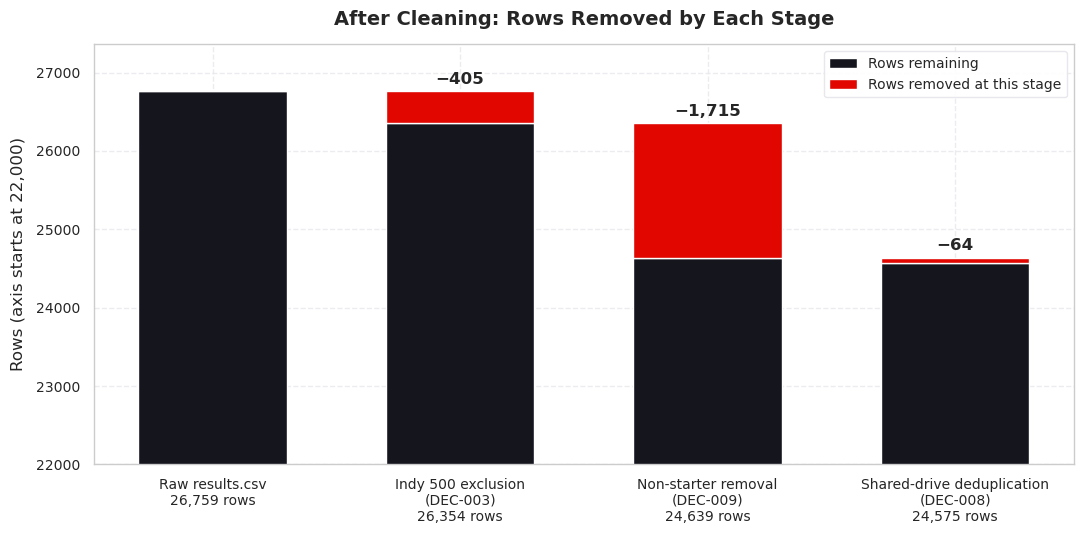

In [27]:
# Task 8.1: rows removed by each cleaning stage
ledger_df = pd.Series(cleaning_ledger, name="rows_remaining").to_frame()
ledger_df["rows_removed"] = -ledger_df["rows_remaining"].diff().fillna(0).astype(int)
display(ledger_df)

labels = [f"{stage.replace(' (', chr(10) + '(')}\n{rows:,} rows" for stage, rows in cleaning_ledger.items()]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(labels, ledger_df["rows_remaining"], color=F1_PALETTE["dark"], width=0.6, label="Rows remaining")
removed = ax.bar(labels, ledger_df["rows_removed"], bottom=ledger_df["rows_remaining"], color=F1_PALETTE["crimson"],
                 width=0.6, label="Rows removed at this stage")
ax.bar_label(removed, labels=[f"−{n:,}" if n else "" for n in ledger_df["rows_removed"]], padding=3, fontweight="bold")
ax.set(title="After Cleaning: Rows Removed by Each Stage", ylabel="Rows (axis starts at 22,000)",
       ylim=(22000, ledger_df["rows_remaining"].iloc[0] + 600))
ax.legend()
save_fig("after_eda_row_count_waterfall")
plt.show()

[FIGURE SAVED] figures/after_eda_entrants_per_race.png


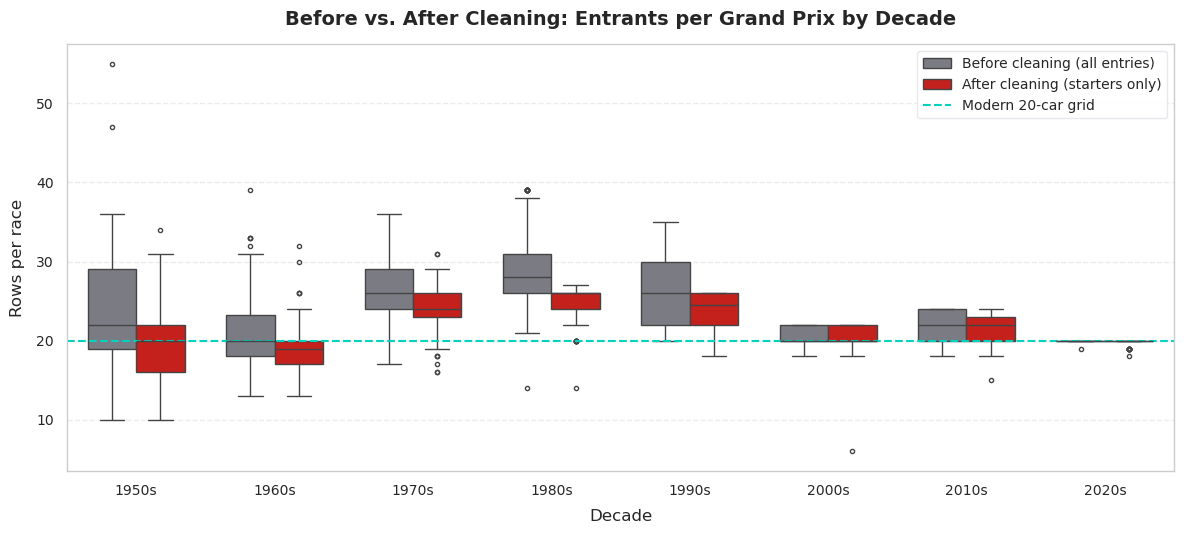

Largest field: {'Before cleaning (all entries)': 55, 'After cleaning (starters only)': 34}


In [28]:
# Task 8.2: entrants per race by decade, before and after
field_sizes = pd.concat([
    raw_with_year.groupby(["year", "raceId"]).size().rename("entrants").reset_index().assign(stage="Before cleaning (all entries)"),
    clean_df.groupby(["year", "raceId"]).size().rename("entrants").reset_index().assign(stage="After cleaning (starters only)"),
])
field_sizes["decade"] = (field_sizes["year"] // 10 * 10).astype(str) + "s"

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=field_sizes, x="decade", y="entrants", hue="stage",
            palette=[F1_PALETTE["gray"], F1_PALETTE["crimson"]], width=0.7, fliersize=3, ax=ax)
ax.axhline(20, color=F1_PALETTE["teal"], linestyle="--", label="Modern 20-car grid")
ax.set(title="Before vs. After Cleaning: Entrants per Grand Prix by Decade", xlabel="Decade", ylabel="Rows per race")
ax.legend(loc="upper right")
save_fig("after_eda_entrants_per_race")
plt.show()
print("Largest field:", field_sizes.groupby("stage", sort=False)["entrants"].max().to_dict())

[FIGURE SAVED] figures/after_eda_missingness.png


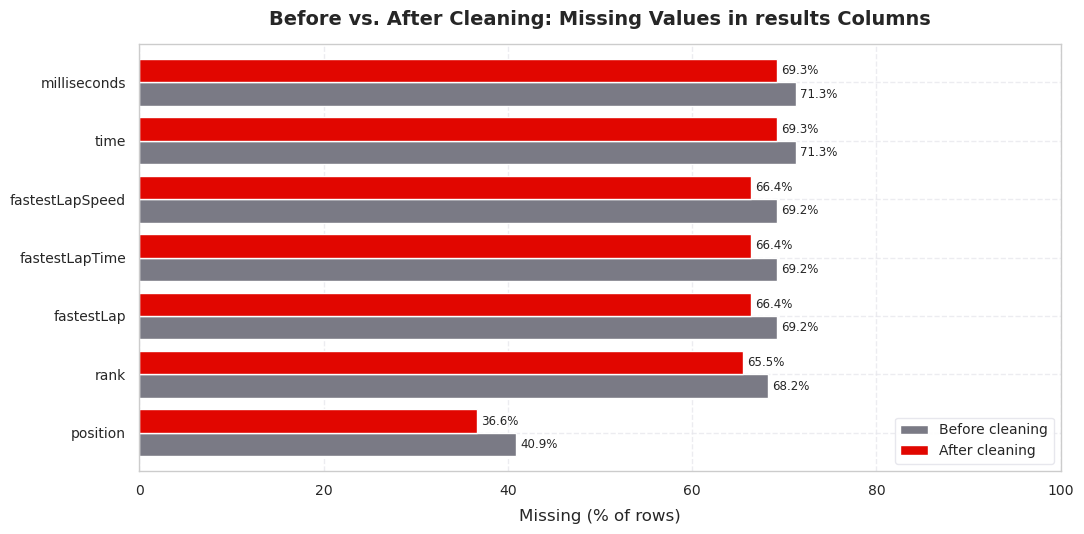

In [29]:
# Task 8.3: missing values in the results columns, before and after
raw_results = raw_dataframes["results"]
null_compare = pd.DataFrame({
    "Before cleaning": raw_results.isna().mean() * 100,
    "After cleaning": clean_df[raw_results.columns].isna().mean() * 100,
})
null_compare = null_compare[null_compare["Before cleaning"] > 0.1].sort_values("Before cleaning")

ax = null_compare.plot.barh(color=[F1_PALETTE["gray"], F1_PALETTE["crimson"]], width=0.8, figsize=(11, 5.5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8.5)
ax.set(title="Before vs. After Cleaning: Missing Values in results Columns", xlabel="Missing (% of rows)", xlim=(0, 100))
ax.legend(loc="lower right")
save_fig("after_eda_missingness")
plt.show()

[FIGURE SAVED] figures/after_eda_podium_base_rate.png


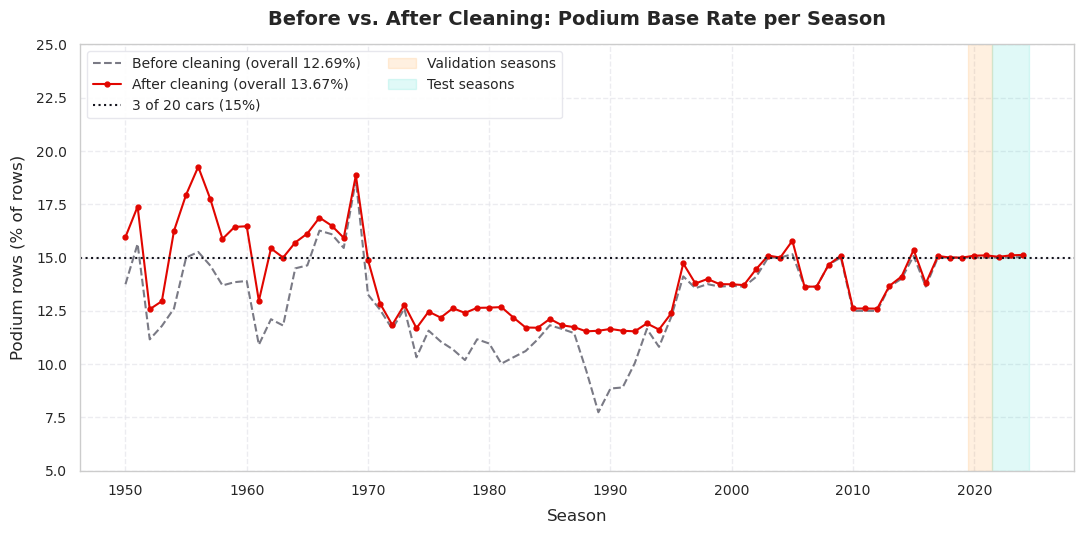

Largest increase: 1956 (+4.00 points)


In [30]:
# Task 8.4: podium base rate per season, before and after
rate_after = clean_df.groupby("year")[TARGET_COLUMN].mean() * 100
clean_podium_rate = clean_df[TARGET_COLUMN].mean() * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(podium_rate_by_season.index, podium_rate_by_season.values, color=F1_PALETTE["gray"], linestyle="--",
        label=f"Before cleaning (overall {raw_podium_rate:.2f}%)")
ax.plot(rate_after.index, rate_after.values, color=F1_PALETTE["crimson"], marker="o", markersize=3.5,
        label=f"After cleaning (overall {clean_podium_rate:.2f}%)")
ax.axhline(15, color=F1_PALETTE["dark"], linestyle=":", label="3 of 20 cars (15%)")
ax.axvspan(VAL_YEARS[0] - 0.5, VAL_YEARS[1] + 0.5, color=F1_PALETTE["orange"], alpha=0.12, label="Validation seasons")
ax.axvspan(TEST_MIN_YEAR - 0.5, clean_df["year"].max() + 0.5, color=F1_PALETTE["teal"], alpha=0.12, label="Test seasons")
ax.set(title="Before vs. After Cleaning: Podium Base Rate per Season", xlabel="Season", ylabel="Podium rows (% of rows)", ylim=(5, 25))
ax.legend(loc="upper left", ncol=2)
save_fig("after_eda_podium_base_rate")
plt.show()

rate_change = (rate_after - podium_rate_by_season).sort_values(ascending=False)
print(f"Largest increase: {rate_change.index[0]} (+{rate_change.iloc[0]:.2f} points)")

[FIGURE SAVED] figures/after_eda_qualifying_coverage.png


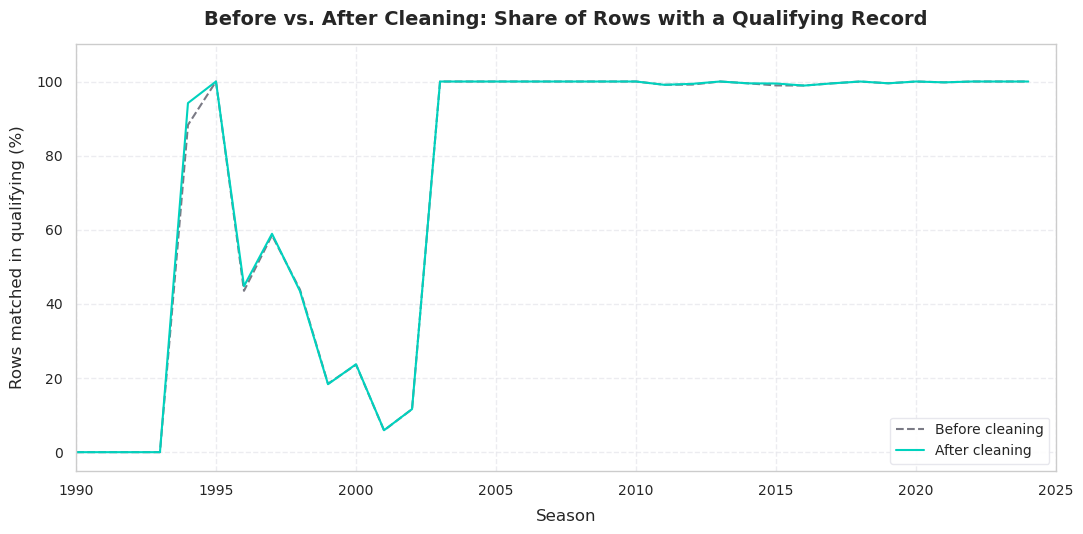

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
Before cleaning,0.0,88.3,100.0,43.5,58.5,43.8,18.5,23.6,5.9,11.6,100.0,100.0
After cleaning,0.0,94.2,100.0,44.8,58.9,43.4,18.3,23.7,5.9,11.6,100.0,100.0


Cleaned rows from 2003 on without a qualifying record: 21


In [31]:
# Task 8.5: share of rows with a qualifying record, before and after
def with_quali_flag(df: pd.DataFrame) -> pd.DataFrame:
    """Return year plus has_quali: does the (raceId, driverId) row have a qualifying record?"""
    merged = df[GRAIN + ["year"]].merge(qualifying_clean[GRAIN], on=GRAIN, how="left", indicator=True)
    return merged.assign(has_quali=merged["_merge"] == "both")

quali_before = with_quali_flag(raw_with_year.drop_duplicates(subset=GRAIN))
quali_after = with_quali_flag(clean_df)
quali_coverage = pd.DataFrame({
    "Before cleaning": quali_before.groupby("year")["has_quali"].mean() * 100,
    "After cleaning": quali_after.groupby("year")["has_quali"].mean() * 100,
})

ax = quali_coverage.plot(color=[F1_PALETTE["gray"], F1_PALETTE["teal"]], style=["--", "-"], figsize=(11, 5.5))
ax.set(title="Before vs. After Cleaning: Share of Rows with a Qualifying Record", xlabel="Season",
       ylabel="Rows matched in qualifying (%)", xlim=(1990, clean_df["year"].max() + 1), ylim=(-5, 110))
ax.legend(loc="lower right")
save_fig("after_eda_qualifying_coverage")
plt.show()

display(quali_coverage.loc[1993:2004].round(1).T)
print(f"Cleaned rows from 2003 on without a qualifying record: {(~quali_after.loc[quali_after['year'] >= 2003, 'has_quali']).sum()}")

In [32]:
# Task 8.6: final types and checks on clean_df
display(pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "null_pct": (clean_df.isna().mean() * 100).round(2),
    "unique": clean_df.nunique(),
}))

numeric_cols = ["raceId", "driverId", "constructorId", "year", "round", "grid", "pit_start", "positionOrder", "laps",
                "points", "milliseconds", "fastestLap", "rank", "fastestLapSpeed", TARGET_COLUMN]
assert all(pd.api.types.is_numeric_dtype(clean_df[col]) for col in numeric_cols), "A numeric column is not numeric"
assert pd.api.types.is_datetime64_any_dtype(clean_df["date"]), "'date' should be a datetime"
assert all(pd.api.types.is_float_dtype(qualifying_clean[col]) for col in ["q1", "q2", "q3"]), "q1-q3 should be float seconds"
assert not clean_df.select_dtypes(exclude="number").isin([r"\N"]).any().any(), r"\N remains in clean_df"
assert "pit_start" not in raw_dataframes["results"].columns, "raw results was changed"
print(f"[STEP 2 COMPLETE] clean_df is ready: {len(clean_df):,} rows x {clean_df.shape[1]} columns.")

,dtype,null_pct,unique
raceId,int64,0.00,1114
driverId,int64,0.00,683
constructorId,int64,0.00,166
date,datetime64[ns],0.00,1114
year,int64,0.00,75
round,int64,0.00,24
race_name,object,0.00,53
circuitId,int64,0.00,77
circuit_name,object,0.00,77
circuit_location,object,0.00,75


[STEP 2 COMPLETE] clean_df is ready: 24,575 rows x 29 columns.


## Hand-Off

`clean_df` has one row per `(raceId, driverId)` and passes the data contract.

| Stage | Rows removed | Rows left |
| :--- | ---: | ---: |
| Raw `results` | | 26,759 |
| Indianapolis 500, 1950–1960 (DEC-003) | 405 | 26,354 |
| Non-starters (DEC-009) | 1,715 | 24,639 |
| Shared-drive duplicates (DEC-008) | 64 | 24,575 |

| Split | Rows | Races | Podiums | Podium rate |
| :--- | ---: | ---: | ---: | ---: |
| Train (≤ 2019) | 22,448 | 1,007 | 3,038 | 13.53% |
| Validation (2020–2021) | 775 | 39 | 117 | 15.10% |
| Test (≥ 2022) | 1,352 | 68 | 204 | 15.09% |

| Object | Contents |
| :--- | :--- |
| `clean_df` | Cleaned results with race and circuit context, `pit_start` and `podium`. Outcome columns are kept for analysis and are blacklisted as features. |
| `qualifying_clean` | `position` renamed to `quali_position`; `q1`–`q3` in seconds. |
| `sprint_clean` | Every non-key column prefixed with `sprint_`. |
| `cleaned_dataframes` | Typed copies of all 14 tables; `results` is the cleaned, deduplicated version. |

**Keep in mind**
- The podium base rate is 13.67% after cleaning (12.69% raw). It reaches 15% only in the modern 20-car seasons.
- Fifteen races have four or five podium rows, because two drivers shared a podium car. They are kept on purpose.
- Qualifying records cover only 6%–59% of rows per season from 1996 to 2002 and are complete from 2003 (21 rows unmatched), so qualifying features need a missing flag and a `grid` fallback.
- DEC-009 and DEC-010 are still marked **Proposed** in the decision log.

---
# 4. Step 3: Data-Engineering Questions (M2)

Three questions, each answered by joining `clean_df` to other tables. Every question ends with the answer, the joins used, and notes on grain, missing values and the pre-race cutoff.

These are descriptive analyses, not model inputs. Outcome columns such as `podium` and `status` are the thing being measured here and stay blacklisted as features. Every grouping variable (grid slot, qualifying position, circuit, nationality, constructor) is known before the race starts.

In [33]:
# Step 3 helpers: statistics imports and a rate table with Wilson 95% intervals
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint


def rate_table(df: pd.DataFrame, by: List[str], event: str) -> pd.DataFrame:
    """Per group: n rows, number of events, rate in % and its Wilson 95% interval."""
    out = df.groupby(by, observed=True)[event].agg(n="size", events="sum").reset_index()
    low, high = proportion_confint(out["events"], out["n"], method="wilson")
    return out.assign(rate=out["events"] / out["n"] * 100, ci_low=low * 100, ci_high=high * 100)

## Task 9: Q1, Front-Row Conversion by Circuit

**Question.** Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era?

"Front row" is computed twice: from the **grid** (`grid` 1 or 2, where the car actually started) and from **qualifying** (`quali_position` 1 or 2, before penalties). The two differ when a top-two qualifier takes a grid penalty.

**DEC-011.** The pre-2014 era is 2003–2013. `qualifying.csv` has no rows before 1994 and covers only 1 to 10 races per season in 1996–2002, so 2003 is the first season where both definitions can be computed on the same races. A circuit is ranked only if it has at least 10 front-row starts in each era.

In [34]:
# Task 9.1: front-row starts under both definitions (DEC-011)
HYBRID_ERA_START: int = 2014
Q1_FIRST_SEASON: int = 2003      # first season with qualifying rows for every race
MIN_FRONT_ROW_STARTS: int = 10   # per circuit, per era
Q1_ERAS: List[str] = [f"{Q1_FIRST_SEASON}–{HYBRID_ERA_START - 1}", f"{HYBRID_ERA_START}–{clean_df['year'].max()}"]

q1_df = (
    clean_df.loc[clean_df["year"] >= Q1_FIRST_SEASON, GRAIN + ["year", "circuitId", "circuit_name", "grid", TARGET_COLUMN]]
    .merge(qualifying_clean[GRAIN + ["quali_position"]], on=GRAIN, how="left", validate="one_to_one")
)
q1_df["era"] = np.where(q1_df["year"] >= HYBRID_ERA_START, Q1_ERAS[1], Q1_ERAS[0])
q1_df["front_row_grid"] = q1_df["grid"].isin([1, 2])
q1_df["front_row_quali"] = q1_df["quali_position"].isin([1, 2])
print(f"Q1 table: {len(q1_df):,} rows, {q1_df['raceId'].nunique()} races, seasons {q1_df['year'].min()}–{q1_df['year'].max()} | "
      f"rows without a qualifying record: {q1_df['quali_position'].isna().sum()}")

# How often the two definitions disagree, and what a lost front-row slot costs
lost = q1_df["front_row_quali"] & ~q1_df["front_row_grid"]
inherited = q1_df["front_row_grid"] & ~q1_df["front_row_quali"]
display(pd.DataFrame({
    "qualified top two": q1_df.groupby("era")["front_row_quali"].sum(),
    "started on front row": q1_df.groupby("era")["front_row_grid"].sum(),
    "qualified top two, started lower": lost.groupby(q1_df["era"]).sum(),
    "podium % of those": (q1_df.loc[lost].groupby("era")[TARGET_COLUMN].mean() * 100).round(1),
    "started on front row, qualified lower": inherited.groupby(q1_df["era"]).sum(),
    "podium % of these": (q1_df.loc[inherited].groupby("era")[TARGET_COLUMN].mean() * 100).round(1),
}))
display(q1_df.loc[lost, "grid"].sub(q1_df.loc[lost, "quali_position"]).describe().round(1).to_frame("grid slots lost").T)

Q1 table: 8,909 rows, 428 races, seasons 2003–2024 | rows without a qualifying record: 21


,qualified top two,started on front row,"qualified top two, started lower",podium % of those,"started on front row, qualified lower",podium % of these
era,,,,,,
2003–2013,398,398,9,22.2,9,55.6
2014–2024,453,453,27,33.3,27,66.7


,count,mean,std,min,25%,50%,75%,max
grid slots lost,36.0,7.2,5.0,1.0,3.0,5.0,10.0,23.0


In [35]:
# Task 9.2: conversion rate per circuit and era, minimum-sample filter, rank correlation
FRONT_ROW_DEFINITIONS = {"Grid position 1–2": "front_row_grid", "Qualifying position 1–2": "front_row_quali"}

q1_rates = pd.concat([
    rate_table(q1_df[q1_df[flag]], ["circuitId", "circuit_name", "era"], TARGET_COLUMN).assign(definition=definition)
    for definition, flag in FRONT_ROW_DEFINITIONS.items()
])
display(q1_rates.groupby(["definition", "era"])[["n", "events"]].sum().assign(rate=lambda d: (d["events"] / d["n"] * 100).round(1)))

# Keep a circuit only if it has enough front-row starts in both eras
n_per_era = q1_rates.pivot(index=["definition", "circuit_name"], columns="era", values="n").fillna(0)
eligible = n_per_era[(n_per_era >= MIN_FRONT_ROW_STARTS).all(axis=1)].index
q1_wide = (
    q1_rates.set_index(["definition", "circuit_name"]).loc[eligible]
    .pivot_table(index=["definition", "circuit_name"], columns="era", values=["rate", "n"])
)
q1_wide[("rate", "change")] = q1_wide[("rate", Q1_ERAS[1])] - q1_wide[("rate", Q1_ERAS[0])]
for era in Q1_ERAS:
    q1_wide[("rank", era)] = q1_wide[("rate", era)].groupby("definition").rank(ascending=False, method="min")
q1_wide = q1_wide.sort_index(axis=1)

for definition in FRONT_ROW_DEFINITIONS:
    table = q1_wide.loc[definition].sort_values(("rate", Q1_ERAS[1]), ascending=False)
    rho, p_value = stats.spearmanr(table[("rate", Q1_ERAS[0])], table[("rate", Q1_ERAS[1])])
    print(f"\n{definition}: {len(table)} circuits with >= {MIN_FRONT_ROW_STARTS} front-row starts in both eras | "
          f"Spearman rho between eras = {rho:.2f} (p = {p_value:.2f})")
    display(table.round(1))

# Do the two definitions rank the circuits the same way within an era?
both = q1_wide["rate"].unstack("definition").dropna()
for era in Q1_ERAS:
    rho, _ = stats.spearmanr(both[(era, "Grid position 1–2")], both[(era, "Qualifying position 1–2")])
    print(f"{era}: Spearman rho between the grid-based and qualifying-based rankings = {rho:.2f}")

n  events  rate
definition              era                         
Grid position 1–2       2003–2013  398     272  68.3
                        2014–2024  453     345  76.2
Qualifying position 1–2 2003–2013  398     269  67.6
                        2014–2024  453     336  74.2


Grid position 1–2: 14 circuits with >= 10 front-row starts in both eras | Spearman rho between eras = 0.36 (p = 0.21)


n                rank                rate                 
era                            2003–2013 2014–2024 2003–2013 2014–2024 2003–2013 2014–2024 change
circuit_name                                                                                     
Circuit de Monaco                   22.0      19.0       1.0       1.0      77.3      89.5   12.2
Suzuka Circuit                      18.0      18.0       4.0       2.0      72.2      88.9   16.7
Yas Marina Circuit                  10.0      22.0      10.0       3.0      60.0      86.4   26.4
Circuit de Barcelona-Catalunya      22.0      22.0       6.0       4.0      68.2      81.8   13.6
Circuit de Spa-Francorchamps        18.0      22.0       4.0       4.0      72.2      81.8    9.6
Autódromo José Carlos Pace          22.0      19.0      12.0       6.0      59.1      78.9   19.9
Shanghai International Circuit      20.0      14.0       8.0       7.0      65.0      78.6   13.6
Circuit Gilles Villeneuve           20.0      18.0      10.0       8.0      60.0      77.8   17.8
Silverstone Circuit                 22.0      24.0       3.0       9.0      72.7      75.0    2.3
Autodromo Nazionale di Monza        22.0      22.0       1.0      10.0      77.3      72.7   -4.5
Albert Park Grand Prix Circuit      22.0      18.0      12.0      11.0      59.1      72.2   13.1
Marina Bay Street Circuit           12.0      18.0      14.0      11.0      58.3      72.2   13.9
Bahrain International Circuit       18.0      24.0       7.0      13.0      66.7      66.7    0.0
Hungaroring                         22.0      22.0       9.0      14.0      63.6      59.1   -4.5


Qualifying position 1–2: 14 circuits with >= 10 front-row starts in both eras | Spearman rho between eras = 0.54 (p = 0.05)


n                rank                rate                 
era                            2003–2013 2014–2024 2003–2013 2014–2024 2003–2013 2014–2024 change
circuit_name                                                                                     
Circuit de Monaco                   22.0      19.0       6.0       1.0      68.2      89.5   21.3
Suzuka Circuit                      18.0      18.0       3.0       2.0      72.2      88.9   16.7
Circuit de Barcelona-Catalunya      22.0      22.0       8.0       3.0      63.6      81.8   18.2
Circuit de Spa-Francorchamps        18.0      22.0       3.0       3.0      72.2      81.8    9.6
Yas Marina Circuit                  10.0      22.0       9.0       3.0      60.0      81.8   21.8
Shanghai International Circuit      20.0      14.0       5.0       6.0      70.0      78.6    8.6
Silverstone Circuit                 22.0      24.0       1.0       7.0      77.3      75.0   -2.3
Autodromo Nazionale di Monza        22.0      22.0       2.0       8.0      72.7      72.7    0.0
Albert Park Grand Prix Circuit      22.0      18.0      11.0       9.0      59.1      72.2   13.1
Circuit Gilles Villeneuve           20.0      18.0       9.0       9.0      60.0      72.2   12.2
Marina Bay Street Circuit           12.0      18.0      14.0       9.0      58.3      72.2   13.9
Autódromo José Carlos Pace          22.0      19.0      11.0      12.0      59.1      68.4    9.3
Bahrain International Circuit       18.0      24.0       7.0      13.0      66.7      66.7    0.0
Hungaroring                         22.0      22.0      11.0      14.0      59.1      59.1    0.0

2003–2013: Spearman rho between the grid-based and qualifying-based rankings = 0.89
2014–2024: Spearman rho between the grid-based and qualifying-based rankings = 0.88


[FIGURE SAVED] figures/de_q1_front_row_conversion.png


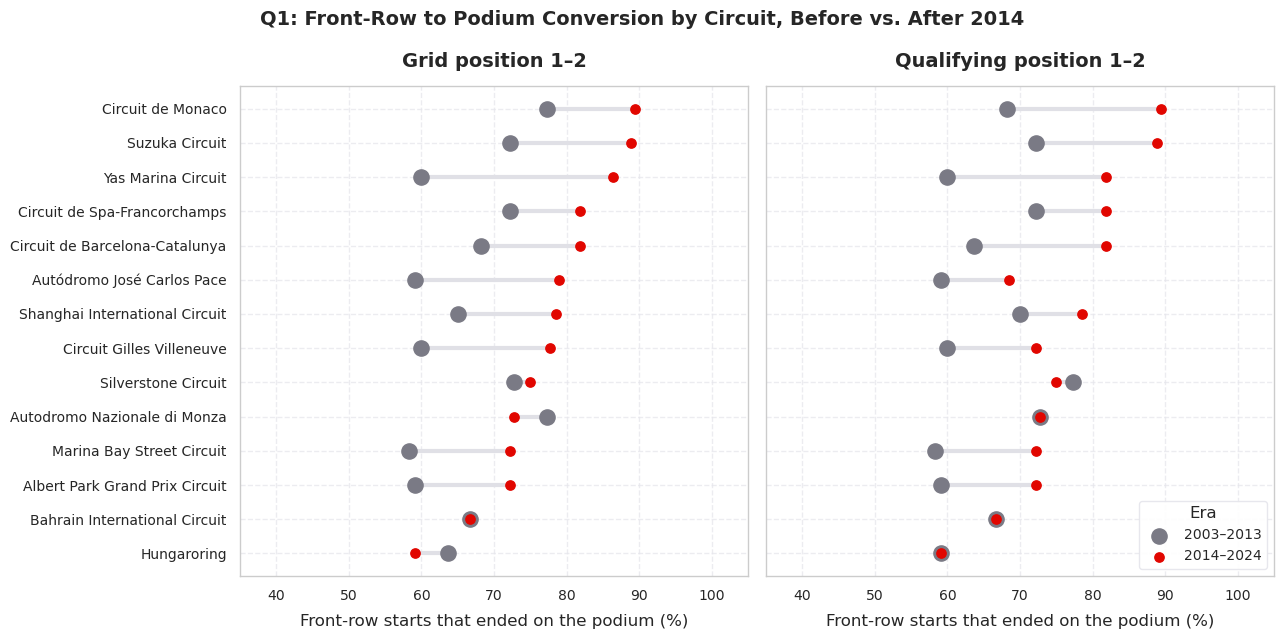

In [36]:
# Task 9.3: dumbbell chart, one panel per front-row definition
circuit_order = q1_wide.loc["Grid position 1–2"].sort_values(("rate", Q1_ERAS[1])).index

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for ax, definition in zip(axes, FRONT_ROW_DEFINITIONS):
    rates = q1_wide.loc[definition, "rate"].reindex(circuit_order)
    ax.hlines(circuit_order, rates[Q1_ERAS[0]], rates[Q1_ERAS[1]], color=F1_PALETTE["light_gray"], linewidth=3, zorder=1)
    ax.scatter(rates[Q1_ERAS[0]], circuit_order, color=F1_PALETTE["gray"], s=120, zorder=2, label=Q1_ERAS[0])
    ax.scatter(rates[Q1_ERAS[1]], circuit_order, color=F1_PALETTE["crimson"], s=45, zorder=3, label=Q1_ERAS[1])
    ax.set(title=definition, xlabel="Front-row starts that ended on the podium (%)", xlim=(35, 105))
axes[1].legend(loc="lower right", title="Era")
fig.suptitle("Q1: Front-Row to Podium Conversion by Circuit, Before vs. After 2014", fontsize=14, fontweight="bold")
save_fig("de_q1_front_row_conversion")
plt.show()

### Q1 answer

**Front-row starts convert more often in the hybrid era, and the circuit ranking is only loosely preserved.**

- **Overall level.** A front-row start ended on the podium 68.3% of the time in 2003–2013 and 76.2% in 2014–2024 (67.6% and 74.2% by qualifying position). The rate rose at 11 of the 14 ranked circuits.
- **Top circuits, 2014–2024.** Monaco (89.5%), Suzuka (88.9%) and Yas Marina (86.4%). The Hungaroring is last (59.1%).
- **Top circuits, 2003–2013.** Monaco and Monza (both 77.3%), then Silverstone (72.7%).
- **Does the ranking change?** Yes. Spearman ρ between the two eras is 0.36 (p = 0.21) on the grid definition and 0.54 (p = 0.05) on the qualifying definition. Monaco and Suzuka stay near the top; Yas Marina climbs from 10th to 3rd and Interlagos from 12th to 6th; Monza falls from 1st to 10th and Silverstone from 3rd to 9th.
- **Grid vs. qualifying.** 9 of 398 top-two qualifiers (2.3%) started lower in 2003–2013 and 27 of 453 (6.0%) in 2014–2024, losing 7 grid slots on average. Those drivers reached the podium 22% and 33% of the time, against 56% and 67% for the drivers who inherited the slot. The two definitions still rank circuits almost identically (ρ = 0.89 and 0.88).

**How far to trust it.** Each circuit has 10 to 24 front-row starts per era, so one race moves a rate by 4 to 10 points. The rise in the overall level is solid; individual rank changes are mostly within that noise.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` + `circuits` (already joined in `clean_df`) + `qualifying` on `(raceId, driverId)`, left join checked one-to-one |
| **Grain** | One row per driver per race. A front-row start is one such row; rates are aggregated per circuit (`circuitId`) and era |
| **Missing values** | Seasons before 2003 are left out (DEC-011). 21 rows from 2003 on have no qualifying record and cannot count as a qualifying front row. Four races have fewer than two front-row rows because a front-row car did not take the start and was removed by DEC-009 (for example the 2005 United States GP). Circuits with fewer than 10 front-row starts in either era are not ranked |
| **Pre-race cutoff** | Both groupings, grid slot and qualifying position, are fixed before the start. `podium` is used only as the outcome |

One limit: qualifying in 2003–2005 used single-lap and aggregate formats, so "qualified in the top two" is not exactly the same test across the whole pre-2014 era.

## Task 10: Q2, Home Advantage Controlling for Grid

**Question.** Do drivers reach the podium more often at a circuit in their home country, compared with drivers who started from a similar grid position?

**DEC-012.** A race is a home race when `circuits.country` is one of the countries mapped from `drivers.nationality`. Edge cases:

- Country names follow `circuits.country` (`British` → `UK`, `American` → `USA`). The circuits table spells the USA two ways; `United States` is folded into `USA`.
- `Monegasque` → `Monaco`, and `East German` → `Germany`.
- Dual nationalities (`American-Italian`, `Argentine-Italian`) have two home countries.
- `Argentinian ` carries a trailing space in the raw table and is stripped.
- Fourteen nationalities, including Finnish, have no circuit in the data. Their drivers are always "away".

All seasons in `clean_df` are used. Grid is bucketed as 1, 2–3, 4–6, 7–10 and 11+; pit-lane starts fall in 11+ after the DEC-010 recoding.

In [37]:
# Task 10.1: nationality -> home country mapping and the home-race flag (DEC-012)
# Country names follow circuits.country. A dual nationality has two home countries.
NATIONALITY_TO_COUNTRIES: Dict[str, Tuple[str, ...]] = {
    "American": ("USA",), "American-Italian": ("USA", "Italy"), "Argentine": ("Argentina",),
    "Argentine-Italian": ("Argentina", "Italy"), "Argentinian": ("Argentina",), "Australian": ("Australia",),
    "Austrian": ("Austria",), "Belgian": ("Belgium",), "Brazilian": ("Brazil",), "British": ("UK",),
    "Canadian": ("Canada",), "Chilean": ("Chile",), "Chinese": ("China",), "Colombian": ("Colombia",),
    "Czech": ("Czech Republic",), "Danish": ("Denmark",), "Dutch": ("Netherlands",), "East German": ("Germany",),
    "Finnish": ("Finland",), "French": ("France",), "German": ("Germany",), "Hungarian": ("Hungary",),
    "Indian": ("India",), "Indonesian": ("Indonesia",), "Irish": ("Ireland",), "Italian": ("Italy",),
    "Japanese": ("Japan",), "Liechtensteiner": ("Liechtenstein",), "Malaysian": ("Malaysia",), "Mexican": ("Mexico",),
    "Monegasque": ("Monaco",), "New Zealander": ("New Zealand",), "Polish": ("Poland",), "Portuguese": ("Portugal",),
    "Rhodesian": ("Rhodesia",), "Russian": ("Russia",), "South African": ("South Africa",), "Spanish": ("Spain",),
    "Swedish": ("Sweden",), "Swiss": ("Switzerland",), "Thai": ("Thailand",), "Uruguayan": ("Uruguay",),
    "Venezuelan": ("Venezuela",),
}
CIRCUIT_COUNTRY_ALIASES: Dict[str, str] = {"United States": "USA"}  # circuits.country spells the USA two ways

q2_df = clean_df[GRAIN + ["year", "circuit_country", "grid", TARGET_COLUMN]].merge(
    cleaned_dataframes["drivers"][["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one"
)
q2_df["nationality"] = q2_df["nationality"].str.strip()   # the raw table holds 'Argentinian ' with a trailing space
q2_df["circuit_country"] = q2_df["circuit_country"].replace(CIRCUIT_COUNTRY_ALIASES)
unmapped = set(q2_df["nationality"]) - set(NATIONALITY_TO_COUNTRIES)
assert not unmapped, f"Nationalities without a home country: {unmapped}"

q2_df["is_home"] = [country in NATIONALITY_TO_COUNTRIES[nat] for nat, country in zip(q2_df["nationality"], q2_df["circuit_country"])]
q2_df["is_home"] = q2_df["is_home"].astype(int)

circuit_countries = set(q2_df["circuit_country"])
no_home_circuit = sorted(nat for nat, countries in NATIONALITY_TO_COUNTRIES.items()
                         if nat in set(q2_df["nationality"]) and not circuit_countries.intersection(countries))
print(f"Home starts: {q2_df['is_home'].sum():,} of {len(q2_df):,} rows ({q2_df['is_home'].mean():.1%})")
print(f"Nationalities whose country never hosts a race in the data ({len(no_home_circuit)}): {', '.join(no_home_circuit)}")
display(q2_df[q2_df["is_home"] == 1].groupby("circuit_country").agg(
    home_starts=(TARGET_COLUMN, "size"), home_podiums=(TARGET_COLUMN, "sum"), drivers=("driverId", "nunique")
).sort_values("home_starts", ascending=False).T)

Home starts: 1,930 of 24,575 rows (7.9%)
Nationalities whose country never hosts a race in the data (14): Chilean, Colombian, Czech, Danish, Finnish, Indonesian, Irish, Liechtensteiner, New Zealander, Polish, Rhodesian, Thai, Uruguayan, Venezuelan


circuit_country,UK,Italy,France,Germany,Brazil,USA,Belgium,Spain,Japan,South Africa,Argentina,Canada,Austria,Australia,Mexico,Netherlands,Switzerland,Sweden,Monaco,Russia,Portugal,Hungary,India,China,Malaysia
home_starts,446,398,206,204,114,112,60,60,53,46,44,32,29,28,24,22,13,12,8,8,5,2,2,1,1
home_podiums,69,30,26,29,20,9,3,9,2,4,12,4,2,0,2,4,1,2,2,0,0,0,0,0,0
drivers,123,78,50,46,27,36,19,11,17,18,18,9,9,5,4,9,6,5,3,3,2,1,1,1,1


In [38]:
# Task 10.2: home vs. away podium rate within each grid bucket
GRID_BUCKET_EDGES: List[int] = [0, 1, 3, 6, 10, 99]
GRID_BUCKET_LABELS: List[str] = ["1", "2–3", "4–6", "7–10", "11+"]
q2_df["grid_bucket"] = pd.cut(q2_df["grid"], bins=GRID_BUCKET_EDGES, labels=GRID_BUCKET_LABELS)
q2_df["venue"] = np.where(q2_df["is_home"] == 1, "Home", "Away")
assert q2_df["grid_bucket"].notna().all(), "A grid position falls outside the buckets"

raw_gap = q2_df.groupby("venue")[TARGET_COLUMN].mean() * 100
print(f"Before controlling for grid: home {raw_gap['Home']:.2f}% vs. away {raw_gap['Away']:.2f}% "
      f"({raw_gap['Home'] - raw_gap['Away']:+.2f} points)")
print("Share of starts from the first three grid slots:",
      (q2_df["grid"].le(3).groupby(q2_df["venue"]).mean() * 100).round(1).to_dict())

q2_rates = rate_table(q2_df, ["grid_bucket", "venue"], TARGET_COLUMN)
q2_wide = q2_rates.pivot(index="grid_bucket", columns="venue", values=["n", "events", "rate"])
q2_wide[("rate", "Home − Away")] = q2_wide[("rate", "Home")] - q2_wide[("rate", "Away")]
display(q2_wide.round(2))

Before controlling for grid: home 11.92% vs. away 13.82% (-1.90 points)
Share of starts from the first three grid slots: {'Away': 13.7, 'Home': 11.8}


n          events         rate                   
venue           Away    Home    Away  Home   Away   Home Home − Away
grid_bucket                                                         
1             1028.0    80.0   668.0  49.0  64.98  61.25       -3.73
2–3           2066.0   148.0  1057.0  82.0  51.16  55.41        4.24
4–6           3103.0   224.0   812.0  61.0  26.17  27.23        1.06
7–10          4103.0   336.0   385.0  25.0   9.38   7.44       -1.94
11+          12345.0  1142.0   207.0  13.0   1.68   1.14       -0.54

In [39]:
# Task 10.3: is the home effect significant once grid is held fixed?
def home_logit(df: pd.DataFrame, grid_term: str) -> Dict[str, float]:
    """Logistic regression podium ~ is_home + grid_term, standard errors clustered by driver."""
    fit = smf.logit(f"{TARGET_COLUMN} ~ is_home + {grid_term}", data=df).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": df["driverId"]})
    low, high = np.exp(fit.conf_int().loc["is_home"])
    return {"rows": len(df), "home odds ratio": np.exp(fit.params["is_home"]), "95% CI low": low, "95% CI high": high,
            "p-value": fit.pvalues["is_home"]}


# Cochran–Mantel–Haenszel: one 2x2 table (venue x podium) per grid bucket
cmh = StratifiedTable([
    pd.crosstab(bucket_df["venue"], bucket_df[TARGET_COLUMN]).loc[["Home", "Away"], [1, 0]].to_numpy()
    for _, bucket_df in q2_df.groupby("grid_bucket", observed=True)
])
cmh_low, cmh_high = cmh.oddsratio_pooled_confint()

q2_df["grid_capped"] = q2_df["grid"].clip(upper=21)               # exact grid slot, 21+ pooled
home_drivers = q2_df.groupby("driverId")["is_home"].transform("max") == 1

q2_tests = pd.DataFrame({
    "CMH test, grid buckets": {"rows": len(q2_df), "home odds ratio": cmh.oddsratio_pooled, "95% CI low": cmh_low,
                               "95% CI high": cmh_high, "p-value": cmh.test_null_odds(correction=True).pvalue},
    "Logit, grid buckets": home_logit(q2_df, "C(grid_bucket)"),
    "Logit, exact grid slot": home_logit(q2_df, "C(grid_capped)"),
    "Logit, grid buckets, drivers with a home race only": home_logit(q2_df[home_drivers], "C(grid_bucket)"),
    "Logit, grid buckets + season decade": home_logit(q2_df.assign(decade=q2_df["year"] // 10 * 10), "C(grid_bucket) + C(decade)"),
}).T
display(q2_tests.round(4))
print(f"Do the buckets share one odds ratio? Breslow–Day p = {cmh.test_equal_odds().pvalue:.3f}")

,rows,home odds ratio,95% CI low,95% CI high,p-value
"CMH test, grid buckets",24575.0,0.9527,0.8023,1.1314,0.6144
"Logit, grid buckets",24575.0,0.9536,0.7869,1.1557,0.6282
"Logit, exact grid slot",24575.0,0.9698,0.7991,1.1769,0.7559
"Logit, grid buckets, drivers with a home race only",20435.0,0.9418,0.7795,1.1378,0.5341
"Logit, grid buckets + season decade",24575.0,0.9362,0.7663,1.1437,0.5188


Do the buckets share one odds ratio? Breslow–Day p = 0.324


[FIGURE SAVED] figures/de_q2_home_advantage.png


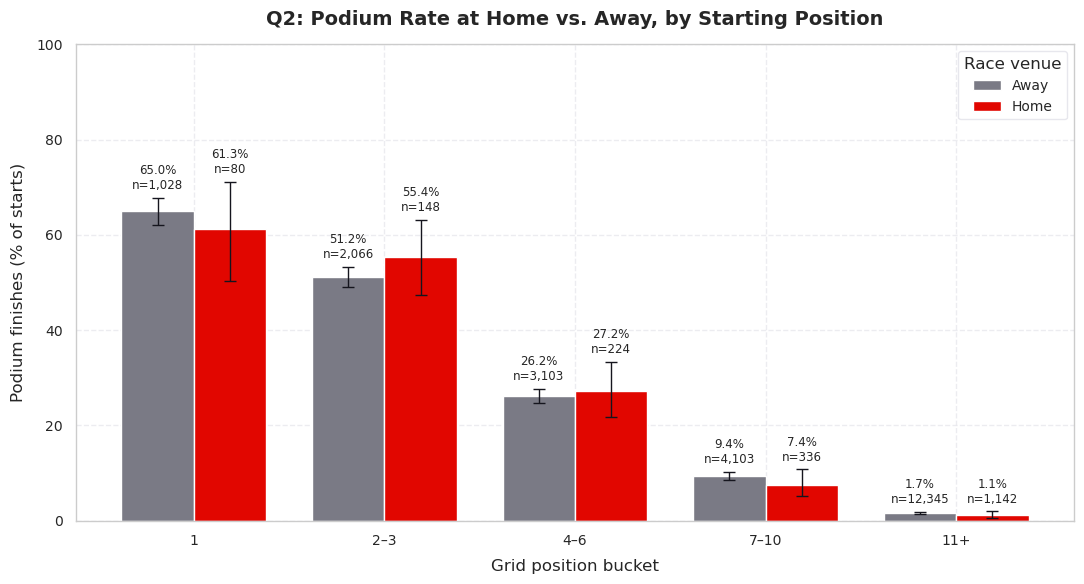

In [40]:
# Task 10.4: grouped bars with Wilson 95% intervals
plot_df = q2_rates.set_index(["grid_bucket", "venue"])
x = np.arange(len(GRID_BUCKET_LABELS))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
for offset, venue, color in [(-bar_width / 2, "Away", F1_PALETTE["gray"]), (bar_width / 2, "Home", F1_PALETTE["crimson"])]:
    rows = plot_df.xs(venue, level="venue").loc[GRID_BUCKET_LABELS]
    bars = ax.bar(x + offset, rows["rate"], bar_width, color=color, label=venue,
                  yerr=[rows["rate"] - rows["ci_low"], rows["ci_high"] - rows["rate"]], capsize=4,
                  error_kw={"ecolor": F1_PALETTE["dark"], "elinewidth": 1})
    ax.bar_label(bars, labels=[f"{rate:.1f}%\nn={n:,}" for rate, n in zip(rows["rate"], rows["n"])], padding=4, fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(GRID_BUCKET_LABELS)
ax.set(title="Q2: Podium Rate at Home vs. Away, by Starting Position", xlabel="Grid position bucket",
       ylabel="Podium finishes (% of starts)", ylim=(0, 100))
ax.legend(title="Race venue")
save_fig("de_q2_home_advantage")
plt.show()

### Q2 answer

**No. Once starting position is held fixed, there is no detectable home advantage.**

- **Before controlling for grid** the home rate is lower: 11.92% at home against 13.82% away. That gap comes from where home drivers start, not from the venue: 11.8% of home starts are from the first three grid slots, against 13.7% of away starts.
- **Within grid buckets** the difference goes both ways: −3.7 points from pole, +4.2 from grid 2–3, +1.1 from 4–6, −1.9 from 7–10 and −0.5 from 11+. Every pair of intervals overlaps.
- **Significance.** The Cochran–Mantel–Haenszel pooled odds ratio for home is 0.95 (95% CI 0.80 to 1.13, p = 0.61). The logistic regression `podium ~ is_home + C(grid_bucket)` agrees: 0.95 (0.79 to 1.16, p = 0.63).
- **Checks.** The result holds with the exact grid slot instead of buckets (0.97), with only drivers who ever had a home race (0.94), and with season decade added (0.94). The Breslow–Day test (p = 0.32) gives no sign that the effect differs between buckets.

The interval rules out a large home advantage: at most about 13% higher odds. It does not rule out a home effect on qualifying itself, because conditioning on grid removes that channel by design.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` + `circuits` (in `clean_df`) + `drivers` on `driverId`, many-to-one |
| **Grain** | One row per driver per race: 24,575 starts, of which 1,930 (7.9%) are home starts |
| **Missing values** | Every nationality is mapped (asserted) and no row lacks a grid slot. Drivers from countries without a circuit stay in the away group; the restricted model above shows this does not drive the result |
| **Pre-race cutoff** | Nationality, circuit country and grid slot are all known before the start. `podium` is the outcome |

Rows are not independent: the same driver appears many times, so the regression standard errors are clustered by driver.

## Task 11: Q3, Mechanical Retirements by Constructor

**Question.** Which constructors have the highest mechanical-retirement rate in 2014–2021 and in 2022–2024?

**DEC-013.** Each of the 139 status labels is mapped to one of four categories. The rule for *mechanical* is strict: the label must name a failed car component or system.

| Category | Examples |
| :--- | :--- |
| finished | `Finished`, `+1 Lap` |
| mechanical | `Engine`, `Gearbox`, `Power Unit`, `Hydraulics`, `Brakes` |
| accident/driver | `Collision`, `Accident`, `Spun off`, `Illness` |
| regulatory/other | `Disqualified`, generic `Retired` and `Withdrew`, `Puncture`, `Out of fuel` |

The rate is mechanical retirements divided by **race starts**. `clean_df` already holds starters only (DEC-009). A constructor is ranked in an era only if it has at least 40 starts there, about one season of a two-car team.

In [41]:
# Task 11.1: status -> category mapping (DEC-013)
# Strict rule: 'mechanical' means the status names a failed car component or system.
ACCIDENT_DRIVER_STATUSES: Set[str] = {
    "Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Stalled",
    "Injured", "Injury", "Eye injury", "Physical", "Driver unwell", "Illness",
}
REGULATORY_OTHER_STATUSES: Set[str] = {
    # steward and rule decisions
    "Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify", "Did not prequalify", "Safety", "Safety concerns",
    # generic labels that give no cause
    "Retired", "Withdrew", "Not classified", "Not restarted", "Handling", "Damage", "Debris",
    # tyres and fuel load: no car component failed
    "Puncture", "Tyre", "Tyre puncture", "Out of fuel", "Fuel", "Refuelling", "Fuel rig",
}
MECHANICAL_STATUSES: Set[str] = {
    # power unit and its ancillaries
    "Engine", "Engine fire", "Engine misfire", "Power Unit", "Power loss", "ERS", "Turbo", "Supercharger", "Battery",
    "Ignition", "Injection", "Distributor", "Magneto", "Spark plugs", "Alternator", "Crankshaft", "Exhaust", "Throttle",
    "Electrical", "Electronics", "Launch control", "Pneumatics",
    # cooling, oil and fuel systems
    "Overheating", "Radiator", "Cooling system", "Water leak", "Water pressure", "Water pump", "Water pipe",
    "Oil leak", "Oil pressure", "Oil pump", "Oil line", "Oil pipe", "Fuel system", "Fuel pressure", "Fuel pump",
    "Fuel leak", "Fuel pipe", "Fire", "Heat shield fire",
    # drivetrain
    "Gearbox", "Transmission", "Clutch", "Differential", "Driveshaft", "Halfshaft", "CV joint", "Axle", "Drivetrain", "Hydraulics",
    # chassis, suspension, brakes, wheels and bodywork
    "Suspension", "Steering", "Track rod", "Brakes", "Brake duct", "Wheel", "Wheel nut", "Wheel rim", "Wheel bearing",
    "Chassis", "Front wing", "Rear wing", "Broken wing", "Undertray", "Vibrations", "Seat", "Driver Seat", "Safety belt",
    # unspecified technical failure
    "Mechanical", "Technical",
}
FINISHED_PATTERN = re.compile(r"^(Finished|\+\d+ Laps?)$")
STATUS_CATEGORIES: List[str] = ["finished", "mechanical", "accident/driver", "regulatory/other"]


def categorise_status(status_text: str) -> str:
    """Map one status label to finished / mechanical / accident/driver / regulatory/other."""
    if FINISHED_PATTERN.match(status_text):
        return "finished"
    if status_text in MECHANICAL_STATUSES:
        return "mechanical"
    if status_text in ACCIDENT_DRIVER_STATUSES:
        return "accident/driver"
    if status_text in REGULATORY_OTHER_STATUSES:
        return "regulatory/other"
    return "unmapped"


status_map = cleaned_dataframes["status"].assign(category=lambda d: d["status"].map(categorise_status))
assert (status_map["category"] != "unmapped").all(), f"Unmapped statuses: {status_map.loc[status_map['category'] == 'unmapped', 'status'].tolist()}"
assert not (MECHANICAL_STATUSES & ACCIDENT_DRIVER_STATUSES) and not (MECHANICAL_STATUSES & REGULATORY_OTHER_STATUSES) \
    and not (ACCIDENT_DRIVER_STATUSES & REGULATORY_OTHER_STATUSES), "A status sits in two categories"
display(status_map.groupby("category").agg(statuses=("status", "size")).reindex(STATUS_CATEGORIES).T)

category,finished,mechanical,accident/driver,regulatory/other
statuses,34,71,12,22


In [42]:
# Task 11.2: mechanical-retirement rate per constructor and era
Q3_ERAS: Dict[str, Tuple[int, int]] = {"2014–2021": (2014, 2021), "2022–2024": (2022, 2024)}
MIN_CONSTRUCTOR_STARTS: int = 40   # about one season of a two-car team

q3_df = (
    clean_df.loc[clean_df["year"] >= 2014, GRAIN + ["constructorId", "year", "statusId", "status"]]
    .merge(status_map[["statusId", "category"]], on="statusId", how="left", validate="many_to_one")
    .merge(cleaned_dataframes["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
           on="constructorId", how="left", validate="many_to_one")
)
q3_df["era"] = np.select([q3_df["year"].between(*years) for years in Q3_ERAS.values()], list(Q3_ERAS), default="")
assert (q3_df["era"] != "").all() and q3_df["category"].notna().all() and q3_df["constructor"].notna().all()
q3_df["mechanical"] = (q3_df["category"] == "mechanical").astype(int)

# What ends a race start in each era, and which statuses carry the mechanical count
display((pd.crosstab(q3_df["era"], q3_df["category"], normalize="index") * 100).round(2)[STATUS_CATEGORIES]
        .assign(starts=q3_df.groupby("era").size()))
display(q3_df[q3_df["mechanical"] == 1].groupby(["era", "status"]).size().unstack("era", fill_value=0)
        .sort_values("2014–2021", ascending=False).head(10).T)

q3_rates = rate_table(q3_df, ["era", "constructor"], "mechanical")
below_threshold = q3_rates[q3_rates["n"] < MIN_CONSTRUCTOR_STARTS]
print(f"Dropped for fewer than {MIN_CONSTRUCTOR_STARTS} starts in an era: "
      + ", ".join(f"{row.constructor} ({row.era}, {row.n} starts)" for row in below_threshold.itertuples()))
q3_rates = q3_rates[q3_rates["n"] >= MIN_CONSTRUCTOR_STARTS].sort_values(["era", "rate"], ascending=[True, False])
for era in Q3_ERAS:
    display(q3_rates[q3_rates["era"] == era].set_index("constructor").drop(columns="era")
            .rename(columns={"n": "starts", "events": "mechanical retirements"}).round(2))

category,finished,mechanical,accident/driver,regulatory/other,starts
era,,,,,
2014–2021,81.97,9.43,6.69,1.91,3245
2022–2024,86.17,5.92,6.66,1.26,1352


status,Engine,Brakes,Gearbox,Power Unit,Suspension,Electrical,Wheel,Power loss,Hydraulics,Oil leak
era,,,,,,,,,,
2014–2021,58,44,32,32,24,13,11,10,9,8
2022–2024,21,4,8,7,1,1,0,2,5,2


Dropped for fewer than 40 starts in an era: Caterham (2014–2021, 33 starts), Marussia (2014–2021, 31 starts)


,starts,mechanical retirements,rate,ci_low,ci_high
constructor,,,,,
Lotus F1,75,14,18.67,11.46,28.93
Toro Rosso,242,39,16.12,12.02,21.27
Renault,199,28,14.07,9.92,19.58
McLaren,316,43,13.61,10.26,17.83
Red Bull,318,34,10.69,7.75,14.57
Sauber,199,21,10.55,7.01,15.59
Haas F1 Team,241,23,9.54,6.44,13.91
AlphaTauri,77,7,9.09,4.47,17.60
Alpine F1 Team,44,4,9.09,3.59,21.16


,starts,mechanical retirements,rate,ci_low,ci_high
constructor,,,,,
Alfa Romeo,88,11,12.50,7.13,21.01
Alpine F1 Team,135,14,10.37,6.28,16.66
AlphaTauri,88,7,7.95,3.91,15.52
Williams,134,8,5.97,3.06,11.34
Aston Martin,134,7,5.22,2.55,10.39
Ferrari,134,7,5.22,2.55,10.39
Haas F1 Team,135,7,5.19,2.53,10.32
Mercedes,136,6,4.41,2.04,9.29
RB F1 Team,48,2,4.17,1.15,13.98


[FIGURE SAVED] figures/de_q3_mechanical_retirements.png


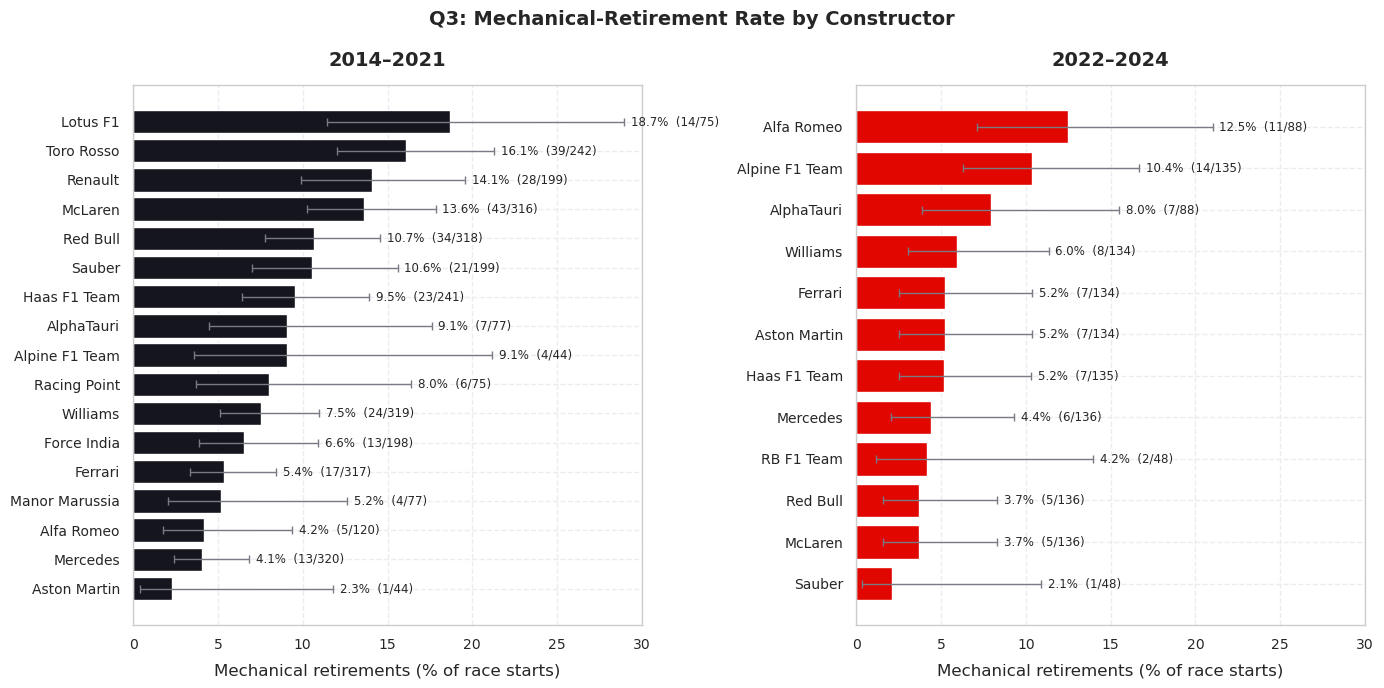

In [43]:
# Task 11.3: constructors ranked within each era
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, era, color in zip(axes, Q3_ERAS, [F1_PALETTE["dark"], F1_PALETTE["crimson"]]):
    rows = q3_rates[q3_rates["era"] == era].sort_values("rate")
    bars = ax.barh(rows["constructor"], rows["rate"], color=color,
                   xerr=[rows["rate"] - rows["ci_low"], rows["ci_high"] - rows["rate"]],
                   error_kw={"ecolor": F1_PALETTE["gray"], "elinewidth": 1, "capsize": 3})
    for bar, row in zip(bars, rows.itertuples()):
        ax.text(row.ci_high + 0.4, bar.get_y() + bar.get_height() / 2, f"{row.rate:.1f}%  ({row.events}/{row.n})",
                va="center", fontsize=8.5)
    ax.set(title=era, xlabel="Mechanical retirements (% of race starts)", xlim=(0, 30))
fig.suptitle("Q3: Mechanical-Retirement Rate by Constructor", fontsize=14, fontweight="bold")
save_fig("de_q3_mechanical_retirements")
plt.show()

n              events                rate                 
era                                       2014–2021 2022–2024 2014–2021 2022–2024 2014–2021 2022–2024 change
team                                                                                                        
Lotus F1 / Renault / Alpine                   318.0     135.0      46.0      14.0     14.47     10.37  -4.10
Toro Rosso / AlphaTauri / RB                  319.0     136.0      46.0       9.0     14.42      6.62  -7.80
McLaren                                       316.0     136.0      43.0       5.0     13.61      3.68  -9.93
Red Bull                                      318.0     136.0      34.0       5.0     10.69      3.68  -7.02
Haas F1 Team                                  241.0     135.0      23.0       7.0      9.54      5.19  -4.36
Sauber / Alfa Romeo                           319.0     136.0      26.0      12.0      8.15      8.82   0.67
Williams                                      319.0     134.0      24.0       8.0      7.52      5.97  -1.55
Force India / Racing Point / Aston Martin     317.0     134.0      20.0       7.0      6.31      5.22  -1.09
Ferrari                                       317.0     134.0      17.0       7.0      5.36      5.22  -0.14
Mercedes                                      320.0     136.0      13.0       6.0      4.06      4.41   0.35

Teams in one era only (not in the chart): Marussia / Manor
Spearman rho between the two eras across 10 teams = 0.24 (p = 0.51)
[FIGURE SAVED] figures/de_q3_mechanical_retirements_lineage.png


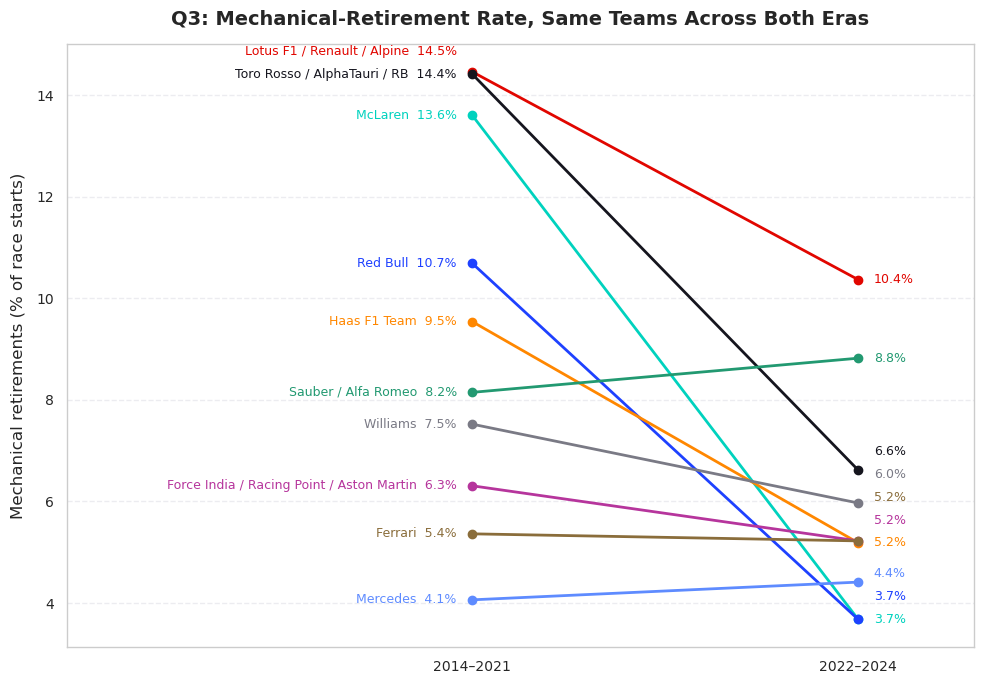

In [44]:
# Task 11.4: the same teams across both eras, with renamed teams merged (DEC-014)
CONSTRUCTOR_LINEAGE: Dict[str, str] = {
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB", "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin",
    "Lotus F1": "Lotus F1 / Renault / Alpine", "Renault": "Lotus F1 / Renault / Alpine", "Alpine F1 Team": "Lotus F1 / Renault / Alpine",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
q3_df["team"] = q3_df["constructor"].replace(CONSTRUCTOR_LINEAGE)

lineage_rates = rate_table(q3_df, ["era", "team"], "mechanical")
lineage_wide = lineage_rates[lineage_rates["n"] >= MIN_CONSTRUCTOR_STARTS].pivot(index="team", columns="era", values=["n", "events", "rate"])
only_one_era = lineage_wide[lineage_wide["rate"].isna().any(axis=1)].index.tolist()
lineage_wide = lineage_wide.dropna()
lineage_wide[("rate", "change")] = lineage_wide[("rate", "2022–2024")] - lineage_wide[("rate", "2014–2021")]
lineage_wide = lineage_wide.sort_values(("rate", "2014–2021"), ascending=False)
rho, p_value = stats.spearmanr(lineage_wide[("rate", "2014–2021")], lineage_wide[("rate", "2022–2024")])
display(lineage_wide.round(2))
print(f"Teams in one era only (not in the chart): {', '.join(only_one_era)}")
print(f"Spearman rho between the two eras across {len(lineage_wide)} teams = {rho:.2f} (p = {p_value:.2f})")

def spread_labels(values: pd.Series, min_gap: float) -> pd.Series:
    """Move label heights apart so that no two sit closer than min_gap."""
    heights: List[float] = []
    ordered = values.sort_values()
    for value in ordered:
        heights.append(value if not heights else max(value, heights[-1] + min_gap))
    return pd.Series(heights, index=ordered.index)


left_y = spread_labels(lineage_wide[("rate", "2014–2021")], min_gap=0.45)
right_y = spread_labels(lineage_wide[("rate", "2022–2024")], min_gap=0.45)
slope_palette = [F1_PALETTE[c] for c in ["crimson", "dark", "teal", "blue", "orange", "green", "gray"]] + ["#B6359C", "#8A6D3B", "#5E8BFF"]
fig, ax = plt.subplots(figsize=(10, 7))
for (team, row), color in zip(lineage_wide["rate"].iterrows(), slope_palette):
    ax.plot([0, 1], [row["2014–2021"], row["2022–2024"]], marker="o", color=color, linewidth=2)
    ax.text(-0.04, left_y[team], f"{team}  {row['2014–2021']:.1f}%", ha="right", va="center", fontsize=9, color=color)
    ax.text(1.04, right_y[team], f"{row['2022–2024']:.1f}%", ha="left", va="center", fontsize=9, color=color)
ax.set_xticks([0, 1])
ax.set_xticklabels(list(Q3_ERAS))
ax.set(title="Q3: Mechanical-Retirement Rate, Same Teams Across Both Eras", ylabel="Mechanical retirements (% of race starts)",
       xlim=(-1.05, 1.3))
ax.grid(axis="x", visible=False)
save_fig("de_q3_mechanical_retirements_lineage")
plt.show()

In [45]:
# Task 11.5: sensitivity. Does the ranking move if the generic 'Retired' label counts as mechanical?
q3_df["mechanical_broad"] = ((q3_df["mechanical"] == 1) | (q3_df["status"] == "Retired")).astype(int)
broad_rates = rate_table(q3_df, ["era", "constructor"], "mechanical_broad")
sensitivity = q3_rates.merge(broad_rates[["era", "constructor", "events", "rate"]], on=["era", "constructor"], suffixes=("_strict", "_broad"))
for col in ["rate_strict", "rate_broad"]:
    sensitivity[col.replace("rate", "rank")] = sensitivity.groupby("era")[col].rank(ascending=False, method="min").astype(int)

print("'Retired' rows per era:", q3_df[q3_df["status"] == "Retired"].groupby("era").size().to_dict())
for era, rows in sensitivity.groupby("era"):
    rho, _ = stats.spearmanr(rows["rate_strict"], rows["rate_broad"])
    print(f"{era}: Spearman rho between the strict and broad rankings = {rho:.2f}")
display(sensitivity.sort_values(["era", "rank_strict"]).set_index(["era", "constructor"])
        [["n", "events_strict", "rate_strict", "rank_strict", "events_broad", "rate_broad", "rank_broad"]].round(2))

'Retired' rows per era: {'2014–2021': 37, '2022–2024': 12}
2014–2021: Spearman rho between the strict and broad rankings = 0.97
2022–2024: Spearman rho between the strict and broad rankings = 0.66


n  events_strict  rate_strict  rank_strict  events_broad  rate_broad  rank_broad
era       constructor                                                                                       
2014–2021 Lotus F1         75             14        18.67            1            17       22.67           1
          Toro Rosso      242             39        16.12            2            43       17.77           2
          Renault         199             28        14.07            3            30       15.08           4
          McLaren         316             43        13.61            4            48       15.19           3
          Red Bull        318             34        10.69            5            35       11.01           7
          Sauber          199             21        10.55            6            25       12.56           5
          Haas F1 Team    241             23         9.54            7            29       12.03           6
          AlphaTauri       77              7         9.09            8             8       10.39           8
          Alpine F1 Team   44              4         9.09            8             4        9.09           9
          Racing Point     75              6         8.00           10             6        8.00          11
          Williams        319             24         7.52           11            28        8.78          10
          Force India     198             13         6.57           12            13        6.57          13
          Ferrari         317             17         5.36           13            17        5.36          14
          Manor Marussia   77              4         5.19           14             6        7.79          12
          Alfa Romeo      120              5         4.17           15             5        4.17          17
          Mercedes        320             13         4.06           16            14        4.38          16
          Aston Martin     44              1         2.27           17             2        4.55          15
2022–2024 Alfa Romeo       88             11        12.50            1            11       12.50           1
          Alpine F1 Team  135             14        10.37            2            14       10.37           3
          AlphaTauri       88              7         7.95            3             7        7.95           5
          Williams        134              8         5.97            4            11        8.21           4
          Aston Martin    134              7         5.22            5             8        5.97           8
          Ferrari         134              7         5.22            5             9        6.72           6
          Haas F1 Team    135              7         5.19            7             7        5.19           9
          Mercedes        136              6         4.41            8             6        4.41          10
          RB F1 Team       48              2         4.17            9             5       10.42           2
          McLaren         136              5         3.68           10             5        3.68          12
          Red Bull        136              5         3.68           10             6        4.41          10
          Sauber           48              1         2.08           12             3        6.25           7

### Q3 answer

**2014–2021: Lotus F1, Toro Rosso and Renault. 2022–2024: Alfa Romeo, Alpine and AlphaTauri.**

| Era | Highest mechanical-retirement rates | Lowest |
| :--- | :--- | :--- |
| 2014–2021 | Lotus F1 18.7% (14 of 75), Toro Rosso 16.1% (39 of 242), Renault 14.1% (28 of 199), McLaren 13.6% (43 of 316) | Aston Martin 2.3% (1 of 44), Mercedes 4.1% (13 of 320) |
| 2022–2024 | Alfa Romeo 12.5% (11 of 88), Alpine 10.4% (14 of 135), AlphaTauri 8.0% (7 of 88) | Sauber 2.1% (1 of 48), Red Bull and McLaren 3.7% (5 of 136) |

- **Reliability improved across the field.** Mechanical retirements fell from 9.43% of starts in 2014–2021 to 5.92% in 2022–2024.
- **Same teams across eras (DEC-014).** With renamed teams merged, the Lotus F1 / Renault / Alpine team is the least reliable in both eras (14.5%, then 10.4%). McLaren improved most, from 13.6% to 3.7%. Only Sauber / Alfa Romeo (+0.7 points) and Mercedes (+0.4) did not improve. The ordering of teams is not stable between eras (Spearman ρ = 0.24, p = 0.51).
- **Sensitivity to the generic `Retired` label** (37 and 12 rows). Counting it as mechanical leaves the 2014–2021 ranking almost unchanged (ρ = 0.97, same top two). In 2022–2024 Alfa Romeo stays first, but the order below it moves (ρ = 0.66): RB F1 Team jumps from 9th to 2nd on 3 `Retired` rows in 48 starts.

**How far to trust it.** The intervals are wide, especially in 2022–2024, where the top three are separated by 4 to 7 retirements. The leaders are clear; the middle of each ranking is not.

| | |
| :--- | :--- |
| **Joins** | `results` + `races` (in `clean_df`) + `status` on `statusId` + `constructors` on `constructorId`, both many-to-one |
| **Grain** | One row per driver per race start, aggregated per constructor and era. 4,597 starts from 2014 on |
| **Missing values** | Every status is mapped (asserted) and every row has a status and a constructor. Caterham and Marussia have fewer than 40 starts in 2014–2021 and are not ranked |
| **Pre-race cutoff** | `status` is recorded after the race and is used here only as the outcome. As a model feature it would be allowed only as a lagged aggregate of earlier races |

One limit: a status such as `Front wing` or `Suspension` names the part that failed, not why. Some of those failures follow contact, so the strict rule can still count a few accident-related retirements as mechanical.